# Crime Data Analysis (2010-2017)

In this notebook, we will load the dataset, explore its columns, perform basic analysis, and visualize relationships between features and the target variable.


### Importing Required Libraries
This cell imports all the Python libraries required for data handling, preprocessing, visualization, and machine learning.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler

sns.set_style('whitegrid')
%matplotlib inline



### Loading the Dataset
This cell loads the crime dataset into a pandas DataFrame for analysis.

In [2]:
# Load dataset
# Update this path to point to your dataset location
# For example: "../archive/Crime_Data_2010_2017.csv" or use an absolute path
dataset_path = r"D:\Crime Prediction\archive\Crime_Data_2010_2017.csv"  # Update this path
# Alternative: dataset_path = "../archive/Crime_Data_2010_2017.csv"  # Relative path option
df = pd.read_csv(dataset_path)

# Number of rows before deletion
rows_before = df.shape[0]
print("Rows before deleting:", rows_before)

# Number of rows to delete
num_delete = 1_200_000

# Randomly select rows to *keep*
df = df.sample(n=rows_before - num_delete, random_state=42)

# Reset index after sampling
df = df.reset_index(drop=True)

# Number of rows after deletion
rows_after = df.shape[0]
print("Rows after deleting:", rows_after)


Rows before deleting: 1584316
Rows after deleting: 384316


### Exploring the Dataset
This cell is used to inspect the dataset structure, data types, and sample records.

In [3]:
print("Shape:", df.shape)

Shape: (384316, 26)


In [4]:
df.head()

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,...,Weapon Description,Status Code,Status Description,Crime Code 1,Crime Code 2,Crime Code 3,Crime Code 4,Address,Cross Street,Location
0,162013944,07/22/2016,07/22/2016,400,20,Olympic,2033,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1307 0216,...,UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,745.0,NaN,NaN,NaN,SERRANO AV,WILSHIRE BL,"(34.0617, -118.3066)"
1,171809182,04/03/2017,04/03/2017,1245,18,Southeast,1863,440,THEFT PLAIN - PETTY ($950 & UNDER),1822 0344 1300 1309,...,NaN,IC,Invest Cont,440.0,NaN,NaN,NaN,400 E 116TH ST,NaN,"(33.9292, -118.2664)"
2,141227253,12/23/2014,12/22/2014,900,12,77th Street,1232,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 0603 0913,...,HAMMER,IC,Invest Cont,745.0,NaN,NaN,NaN,3400 W 59TH ST,NaN,"(33.9872, -118.3308)"
3,130307583,03/01/2013,02/28/2013,2300,3,Southwest,358,440,THEFT PLAIN - PETTY ($950 & UNDER),1251 0344,...,NaN,IC,Invest Cont,440.0,NaN,NaN,NaN,1000 W 34TH ST,NaN,"(34.0243, -118.2876)"
4,121316613,08/01/2012,07/28/2012,630,13,Newton,1317,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329,...,NaN,IC,Invest Cont,745.0,NaN,NaN,NaN,1300 S CENTRAL AV,NaN,"(34.0294, -118.246)"


### Data Processing Step
This cell performs an intermediate processing step required for the crime prediction pipeline.

In [5]:
df.tail()

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,...,Weapon Description,Status Code,Status Description,Crime Code 1,Crime Code 2,Crime Code 3,Crime Code 4,Address,Cross Street,Location
384311,110309682,04/02/2011,04/01/2011,2200,3,Southwest,396,510,VEHICLE - STOLEN,NaN,...,NaN,IC,Invest Cont,510.0,NaN,NaN,NaN,900 W 43RD ST,NaN,"(34.0055, -118.29)"
384312,102022283,10/19/2010,10/18/2010,2245,20,Olympic,2079,510,VEHICLE - STOLEN,NaN,...,NaN,IC,Invest Cont,510.0,NaN,NaN,NaN,PICO BL,MAGNOLIA AV,"(34.0473, -118.2864)"
384313,131708010,03/25/2013,03/24/2013,2200,17,Devonshire,1745,330,BURGLARY FROM VEHICLE,1307 0344 1402,...,NaN,IC,Invest Cont,330.0,998.0,NaN,NaN,10300 LINDLEY AV,NaN,"(34.2573, -118.5273)"
384314,111520966,11/18/2011,01/01/2011,700,15,N Hollywood,1547,341,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LI...",1212,...,NaN,IC,Invest Cont,341.0,NaN,NaN,NaN,11600 BURBANK BL,NaN,"(34.1722, -118.3844)"
384315,131817631,10/21/2013,10/21/2013,1215,18,Southeast,1826,330,BURGLARY FROM VEHICLE,0344,...,NaN,IC,Invest Cont,330.0,NaN,NaN,NaN,103RD,COMPTON,"(33.9432, -118.2462)"


 This dataset contains crime records collected over multiple years, capturing detailed information about reported incidents. It includes attributes such as the date and time of occurrence, geographic area and reporting district, crime codes and descriptions, victim demographics (age, sex, and descent), premise details, case status, and location information. These features provide a comprehensive view of crime patterns and are used to analyze trends and support crime prediction modeling.

### size before dropping columns

In [6]:
print("Shape before dropping columns:", df.shape)

Shape before dropping columns: (384316, 26)


In [7]:
print(df.columns.tolist())

['DR Number', 'Date Reported', 'Date Occurred', 'Time Occurred', 'Area ID', 'Area Name', 'Reporting District', 'Crime Code', 'Crime Code Description', 'MO Codes', 'Victim Age', 'Victim Sex', 'Victim Descent', 'Premise Code', 'Premise Description', 'Weapon Used Code', 'Weapon Description', 'Status Code', 'Status Description', 'Crime Code 1', 'Crime Code 2', 'Crime Code 3', 'Crime Code 4', 'Address', 'Cross Street', 'Location ']


In [8]:
essential_cols = [
    'Date Occurred', 'Time Occurred',
    'Area ID', 'Area Name', 'Reporting District',
    'Crime Code', 'Crime Code Description',
    'Victim Age', 'Victim Sex', 'Victim Descent','Weapon Description',
    'Location '
]
df = df.dropna(subset=essential_cols)

df = df.copy()  # ensure df is a copy, not a view

df.loc[:, 'Premise Code'] = df['Premise Code'].fillna(-1)
df.loc[:, 'Premise Description'] = df['Premise Description'].fillna('Unknown')
df.loc[:, 'MO Codes'] = df['MO Codes'].fillna('None')
df.loc[:, 'Status Code'] = df['Status Code'].fillna('Unknown')

cols_to_drop = [
    'Weapon Used Code','Crime Code 1',
    'Crime Code 2', 'Crime Code 3', 'Crime Code 4',
    'Cross Street'
]
df = df.drop(columns=cols_to_drop, errors='ignore')  # ignore missing columns


### Data Processing Step
This cell performs an intermediate processing step required for the crime prediction pipeline. and tells the columns remained after dropping the unneccessary ones

In [9]:
df.head()

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Address,Location
0,162013944,07/22/2016,07/22/2016,400,20,Olympic,2033,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1307 0216,58.0,F,B,122.0,"VEHICLE, PASSENGER/TRUCK",UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,SERRANO AV,"(34.0617, -118.3066)"
2,141227253,12/23/2014,12/22/2014,900,12,77th Street,1232,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 0603 0913,49.0,M,H,501.0,SINGLE FAMILY DWELLING,HAMMER,IC,Invest Cont,3400 W 59TH ST,"(33.9872, -118.3308)"
12,100209452,04/07/2010,04/06/2010,1630,2,Rampart,245,624,BATTERY - SIMPLE ASSAULT,0416 0444 0602 0554 1251 1258,11.0,F,H,502.0,"MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)","STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)",AA,Adult Arrest,300 S ALVARADO ST,"(34.063, -118.2727)"
16,171115607,08/25/2017,08/25/2017,1840,11,Northeast,1124,930,CRIMINAL THREATS - NO WEAPON DISPLAYED,1803 0421,41.0,M,H,501.0,SINGLE FAMILY DWELLING,VERBAL THREAT,IC,Invest Cont,3200 DREW ST,"(34.1186, -118.245)"
17,100818729,11/30/2010,11/29/2010,2100,8,West LA,849,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329,22.0,M,W,122.0,"VEHICLE, PASSENGER/TRUCK",ROCK/THROWN OBJECT,IC,Invest Cont,1000 S CORNING ST,"(34.0594, -118.3772)"


The dataset was cleaned by removing unnecessary columns and handling missing values, retaining only key features such as crime type, time and location details, victim demographics, premise information, and case status for effective crime analysis and prediction.

In [10]:
# List all columns
df.columns


Index(['DR Number', 'Date Reported', 'Date Occurred', 'Time Occurred',
       'Area ID', 'Area Name', 'Reporting District', 'Crime Code',
       'Crime Code Description', 'MO Codes', 'Victim Age', 'Victim Sex',
       'Victim Descent', 'Premise Code', 'Premise Description',
       'Weapon Description', 'Status Code', 'Status Description', 'Address',
       'Location '],
      dtype='object')

### Exploring the Dataset
This cell is used to inspect the dataset structure, how your data is organized and stored.

In [11]:
# Basic info: data types, non-null counts
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 121153 entries, 0 to 384309
Data columns (total 20 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   DR Number               121153 non-null  int64  
 1   Date Reported           121153 non-null  object 
 2   Date Occurred           121153 non-null  object 
 3   Time Occurred           121153 non-null  int64  
 4   Area ID                 121153 non-null  int64  
 5   Area Name               121153 non-null  object 
 6   Reporting District      121153 non-null  int64  
 7   Crime Code              121153 non-null  int64  
 8   Crime Code Description  121153 non-null  object 
 9   MO Codes                121153 non-null  object 
 10  Victim Age              121153 non-null  float64
 11  Victim Sex              121153 non-null  object 
 12  Victim Descent          121153 non-null  object 
 13  Premise Code            121153 non-null  float64
 14  Premise Description     1

### Exploring the Dataset
This cell is used to inspect the statistical summary of the dataset.

In [12]:
df.describe()


,DR Number,Time Occurred,Area ID,Reporting District,Crime Code,Victim Age,Premise Code
count,1.211530e+05,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000
mean,1.357479e+08,1362.245830,10.901100,1136.341263,525.590146,34.659034,317.184618
std,2.267709e+07,684.677177,6.208553,618.984819,239.884555,14.872485,209.600117
min,9.123193e+07,1.000000,1.000000,100.000000,110.000000,10.000000,101.000000
25%,1.120202e+08,910.000000,5.000000,541.000000,230.000000,23.000000,102.000000
50%,1.401181e+08,1500.000000,12.000000,1218.000000,624.000000,32.000000,247.000000
75%,1.520172e+08,1930.000000,16.000000,1687.000000,626.000000,45.000000,502.000000
max,1.721165e+08,2359.000000,21.000000,2198.000000,956.000000,99.000000,968.000000


In [13]:
# Distribution of target column
target_counts = df['Area Name'].value_counts()
print("Total records:", df['Area Name'].count())
print("\nDistribution of 'Area Name':\n")
print(target_counts)


Total records: 121153

Distribution of 'Area Name':

Area Name
77th Street    11980
Southeast      10081
Southwest       9462
Newton          7302
Rampart         6802
Central         6390
Olympic         6355
Mission         5627
Hollywood       5422
N Hollywood     4985
Hollenbeck      4978
Harbor          4727
Wilshire        4688
Pacific         4669
Northeast       4657
Topanga         4431
Van Nuys        4264
Foothill        4190
West Valley     3710
Devonshire      3430
West LA         3003
Name: count, dtype: int64


### Size after dropping columns

In [14]:
print("Shape after dropping columns:", df.shape)


Shape after dropping columns: (121153, 20)


### Data Processing Step
This cell performs an intermediate processing step required for the crime prediction pipeline.

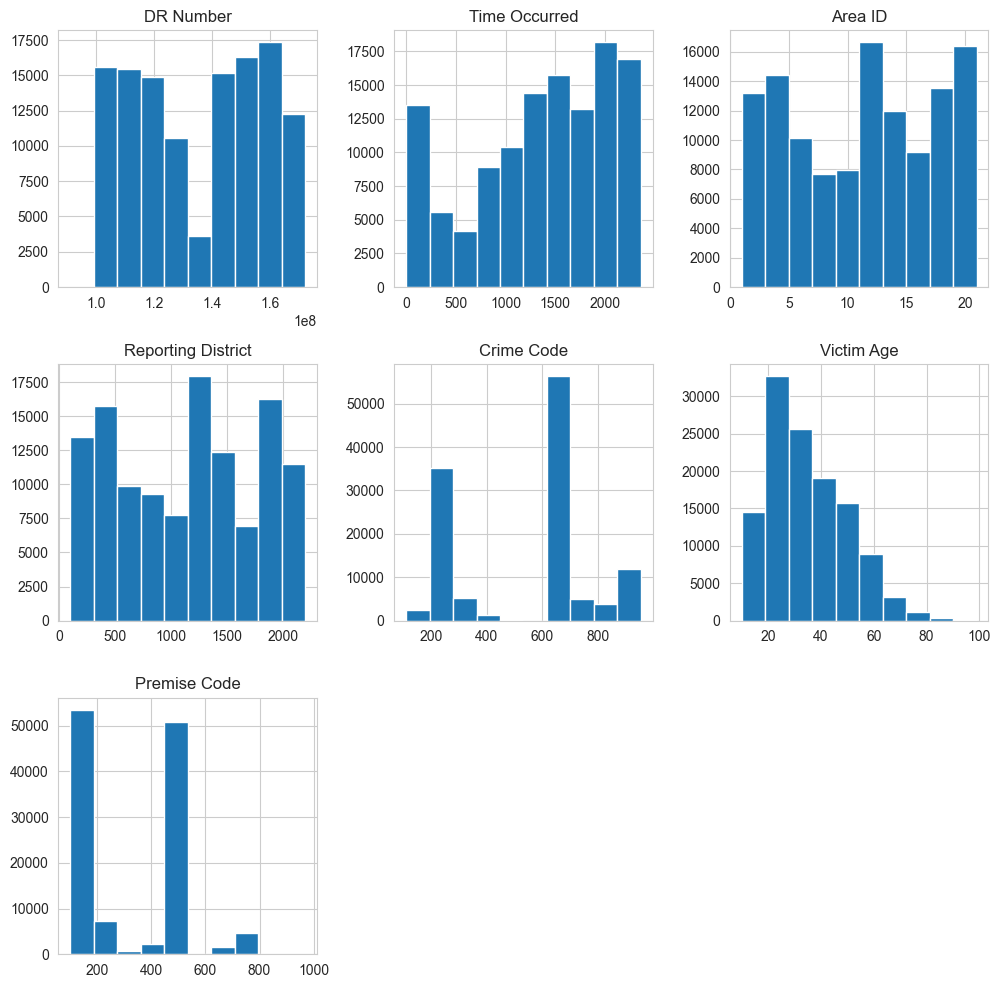

In [15]:
# plot histograms for each variable
df.hist(figsize = (12, 12))
plt.show()

### Handling Missing Values
This cell checks for and handles missing values in the dataset.

In [16]:
df.isnull().sum()

DR Number                 0
Date Reported             0
Date Occurred             0
Time Occurred             0
Area ID                   0
Area Name                 0
Reporting District        0
Crime Code                0
Crime Code Description    0
MO Codes                  0
Victim Age                0
Victim Sex                0
Victim Descent            0
Premise Code              0
Premise Description       0
Weapon Description        0
Status Code               0
Status Description        0
Address                   0
Location                  0
dtype: int64

there are no missing values in this dataset

### Graphical Visualisation Of The Crime Occurrences Over Time
This cell imports all the Python libraries required for data handling, preprocessing, visualization, and machine learning. 

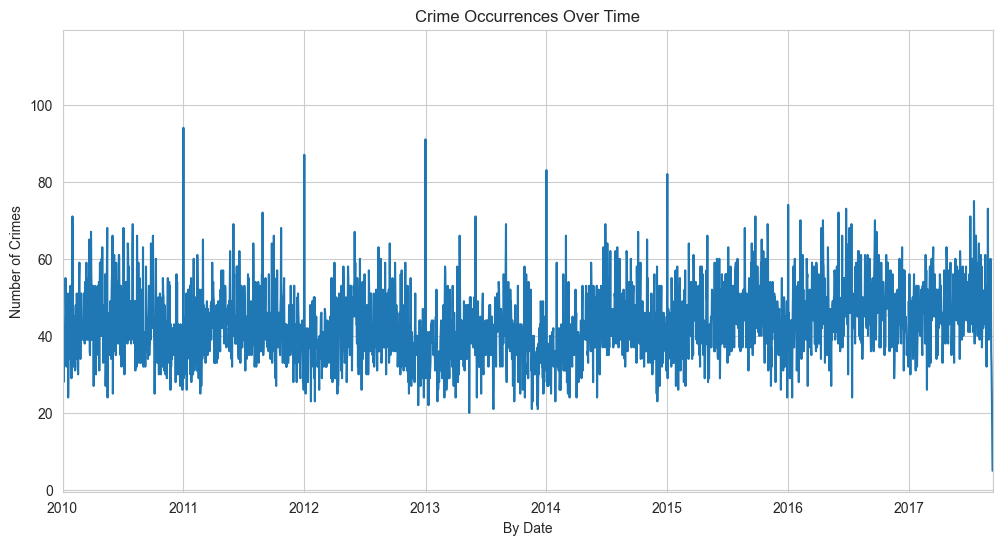

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert 'Date Occurred' to datetime
df['Date Occurred'] = pd.to_datetime(df['Date Occurred'], errors='coerce')

# Count crimes per day
crimes_by_date = df['Date Occurred'].value_counts().sort_index()

# Plot
plt.figure(figsize=(12,6))
crimes_by_date.plot()
plt.title("Crime Occurrences Over Time")
plt.xlabel("By Date")
plt.ylabel("Number of Crimes")
plt.grid(True)
plt.show()




this boxplot shows the number of crimes that have occured by date (per day) over the years

### Identify Top 5 Most Frequent Crimes
Identifying the top 5 most frequently reported crimes in the dataset for focused analysis.
Converting the Date Occurred column to a datetime type and extract the year for trend analysis. Invalid dates are automatically handled.

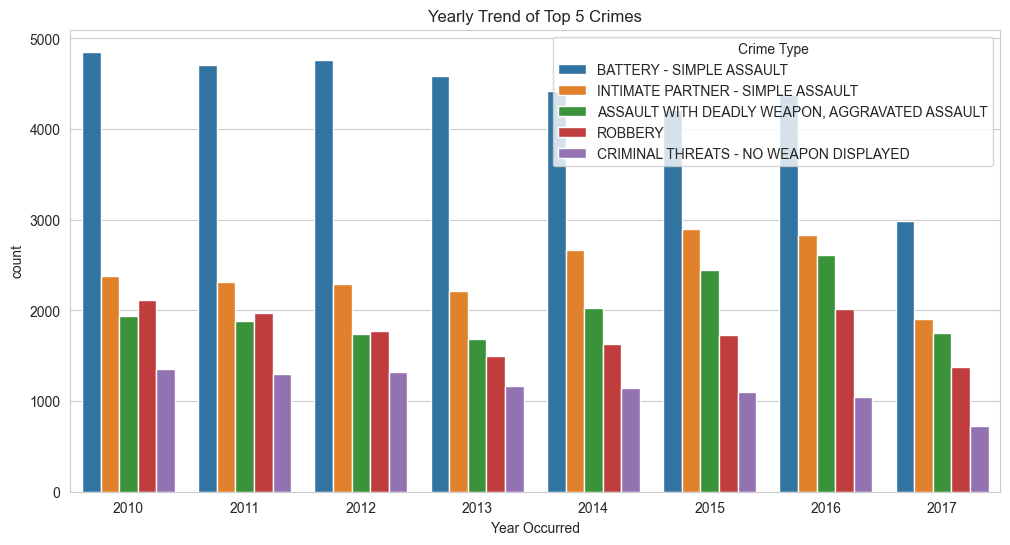

In [18]:

df['Date Occurred'] = pd.to_datetime(df['Date Occurred'], errors='coerce')
df['Year Occurred'] = df['Date Occurred'].dt.year


top_crimes = df['Crime Code Description'].value_counts().index[:5]


df_top_crimes = df[df['Crime Code Description'].isin(top_crimes)]


plt.figure(figsize=(12,6))
sns.countplot(data=df_top_crimes, x='Year Occurred', hue='Crime Code Description',
              order=sorted(df_top_crimes['Year Occurred'].dropna().unique()))
plt.title('Yearly Trend of Top 5 Crimes')
plt.legend(title='Crime Type')
plt.show()


### Filter Dataset For Top Areas and Top Crimes
Visualize the distribution of the top 5 crimes across the top 10 areas. The count plot highlights which crime types are most common in each area


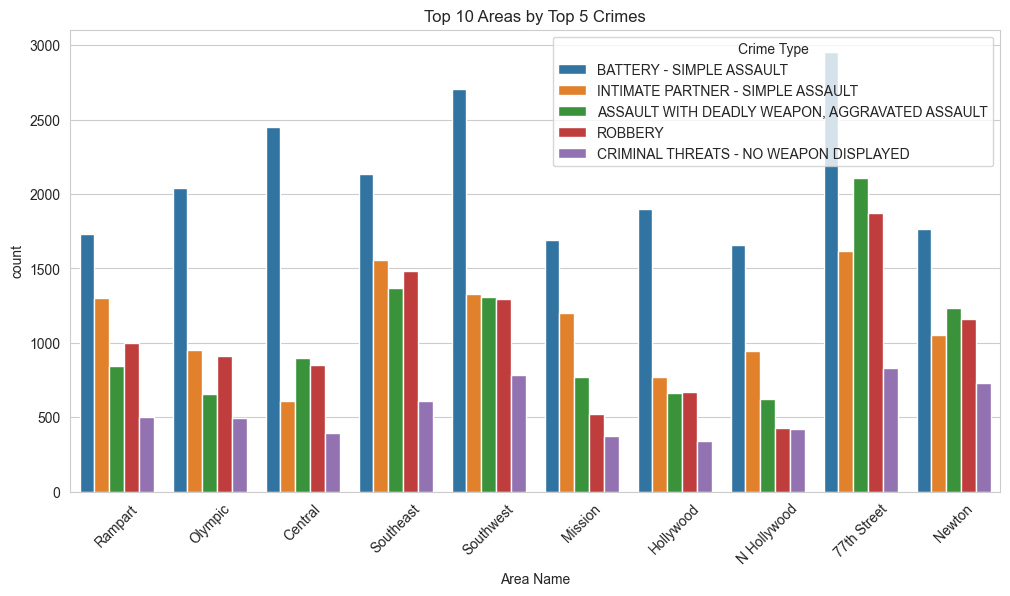

In [19]:
# Top 10 areas
top_areas = df['Area Name'].value_counts().index[:10]

# Filter dataset for top areas and top 5 crimes
df_area_top = df[(df['Area Name'].isin(top_areas)) & (df['Crime Code Description'].isin(top_crimes))]

# Plot
plt.figure(figsize=(12,6))
sns.countplot(data=df_area_top, x='Area Name', hue='Crime Code Description')
plt.xticks(rotation=45)
plt.title('Top 10 Areas by Top 5 Crimes')
plt.legend(title='Crime Type')
plt.show()


### Correlation Heatmap of Numeric Features
This heatmap visualizes the relationships between numeric variables in the crime dataset. Strong positive or negative correlations are indicated by red or blue colors, respectively. It helps identify which variables may be related and can guide feature selection for modeling.

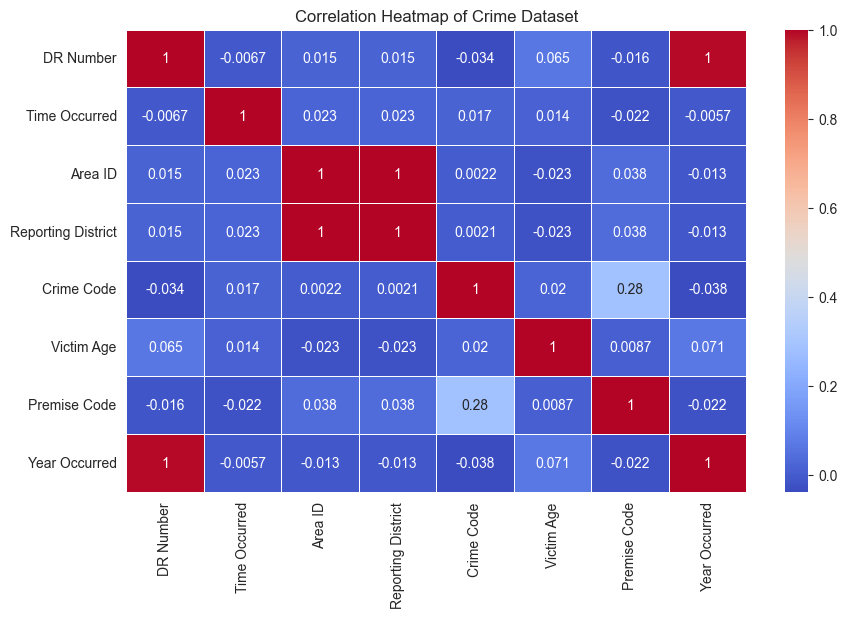

In [20]:
# co relation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Crime Dataset")
plt.show()

### Top 10 Crime Types
Visualize the frequency of the top 10 crime types using a bar chart.

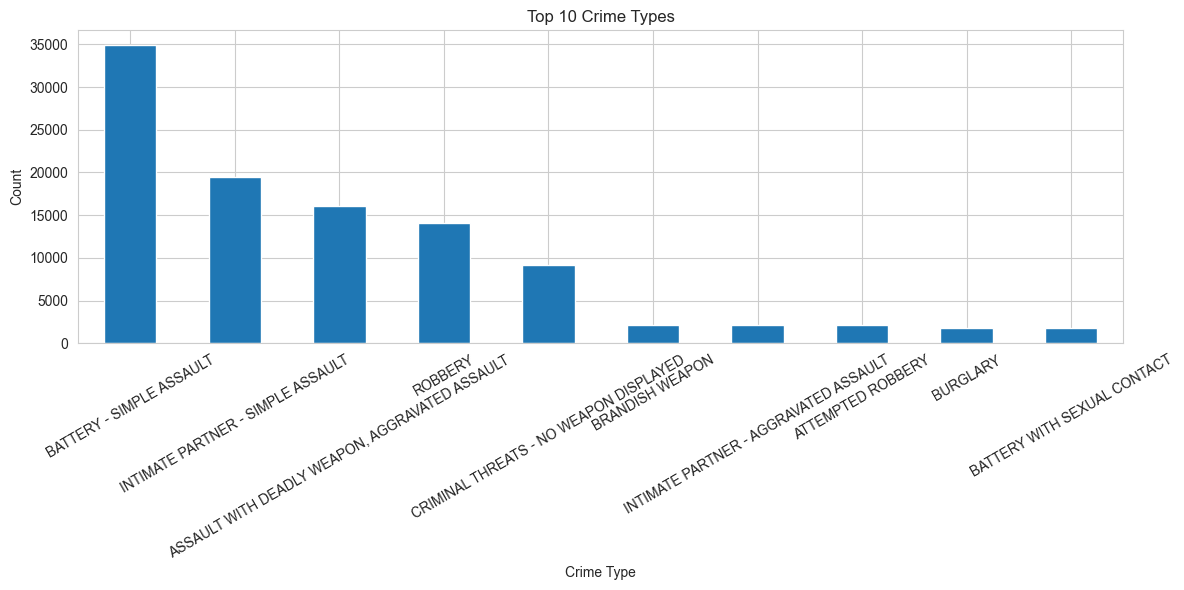

In [21]:
if 'Crime Code Description' in df.columns:
    plt.figure(figsize=(12,6))
    top_crimes = df['Crime Code Description'].value_counts().head(10)  # Top 10 only
    top_crimes.plot(kind='bar')
    plt.title("Top 10 Crime Types")
    plt.xlabel("Crime Type")
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### Crime Trends Over The Years
visualise the number of crimes occurred over the years

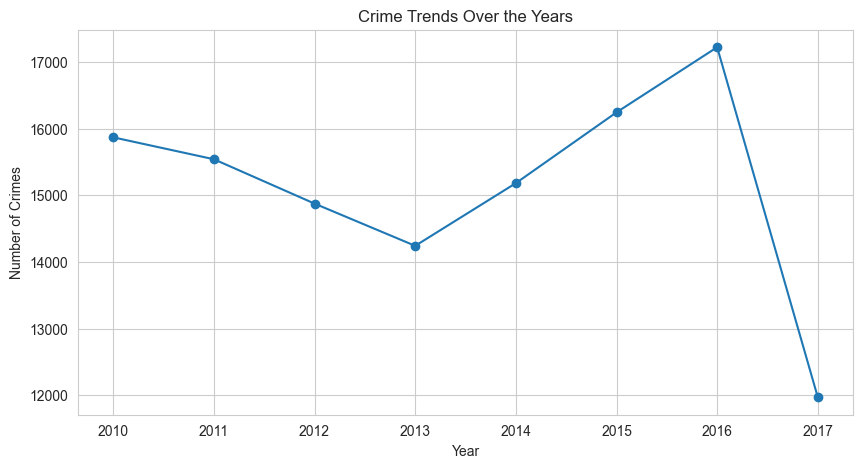

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

# Make sure 'Date Occurred' is datetime
df['Date Occurred'] = pd.to_datetime(df['Date Occurred'], errors='coerce')

# Extract year from the date
df['Year'] = df['Date Occurred'].dt.year

# Group by year and count number of crimes
yearly_data = df.groupby('Year').size()

# Plot
plt.figure(figsize=(10,5))
plt.plot(yearly_data.index, yearly_data.values, marker='o', linestyle='-')
plt.title("Crime Trends Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")
plt.grid(True)
plt.show()


this plot shows the number of crimes that occurred grouped by year and we can clearly see that in comparison with other years, in 2017 the no of crimes significantly dropped according to our dataset.

In [23]:
import sys
!{sys.executable} -m pip install wordcloud


### Word Cloud – Crime Code Description

This visualization highlights the most frequent crime-related terms in the dataset.Larger words indicate higher frequency of occurrence.Common terms represent dominant crime types reported in the data.This helps in quickly identifying prevalent crime patterns without numerical aggregation.

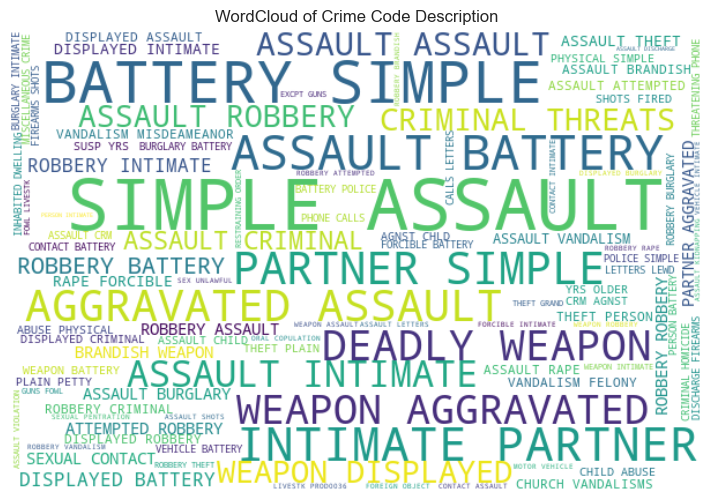

In [24]:
import pandas as pd
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Choose categorical/text column from crime dataset
categorical_col = ['Crime Code Description']

textualcol = []
for col in categorical_col:
    if col in df.columns:
        text_data = df[col].dropna().astype(str).tolist()
        textualcol.extend(text_data)

# Combine all text
text = ' '.join(textualcol)

# Generate word cloud
wordcloud = WordCloud(
    width=600,
    height=400,
    background_color='white',
    max_words=100
).generate(text)

# Plot
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud of Crime Code Description")
plt.show()


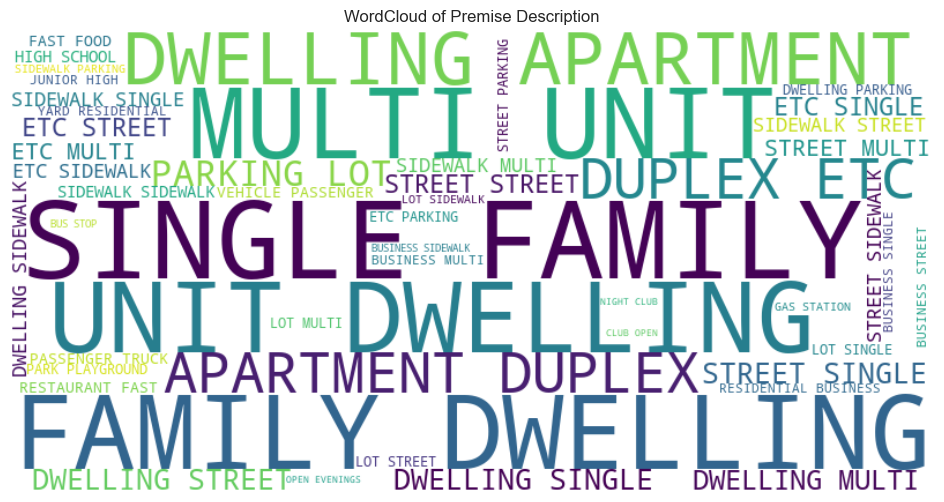

In [25]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Collect text data from Premise Description
text_data = df['Premise Description'].dropna().astype(str)

# Combine into a single string
text = ' '.join(text_data)

# Generate WordCloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=50
).generate(text)

# Plot
plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud of Premise Description")
plt.show()


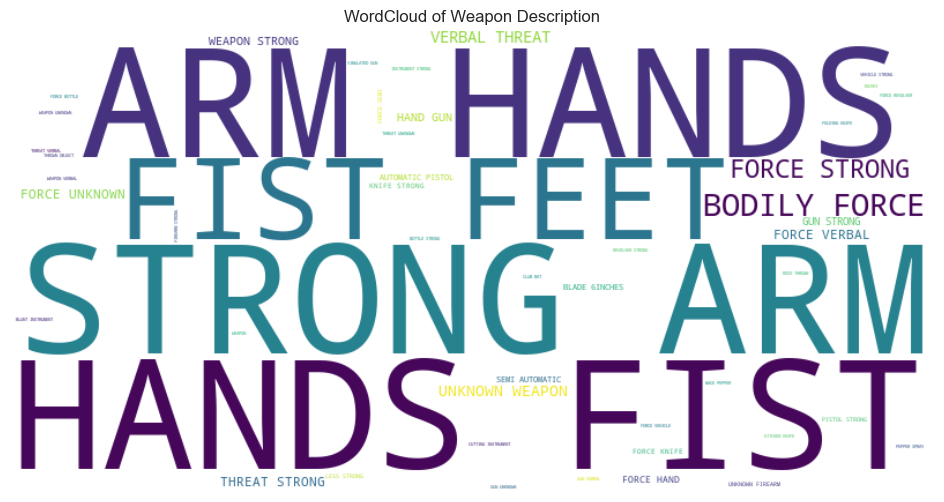

In [26]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Collect text data from Weapon Description
text_data = df['Weapon Description'].dropna().astype(str)

# Combine into a single string
text = ' '.join(text_data)

# Generate WordCloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=50
).generate(text)

# Plot
plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud of Weapon Description")
plt.show()


# Outlier Handling

### Victim Age Statistics
This output summarizes the distribution of victim ages, including average age, variability, and range. It helps identify trends and potential outliers in victim demographics.

In [27]:
print(df['Victim Age'].describe())


count    121153.000000
mean         34.659034
std          14.872485
min          10.000000
25%          23.000000
50%          32.000000
75%          45.000000
max          99.000000
Name: Victim Age, dtype: float64


### Boxplot of Victim Age
This boxplot visualizes the distribution of victim ages, highlighting the median, spread, and potential outliers. It helps identify unusual age values that may require preprocessing before model training.

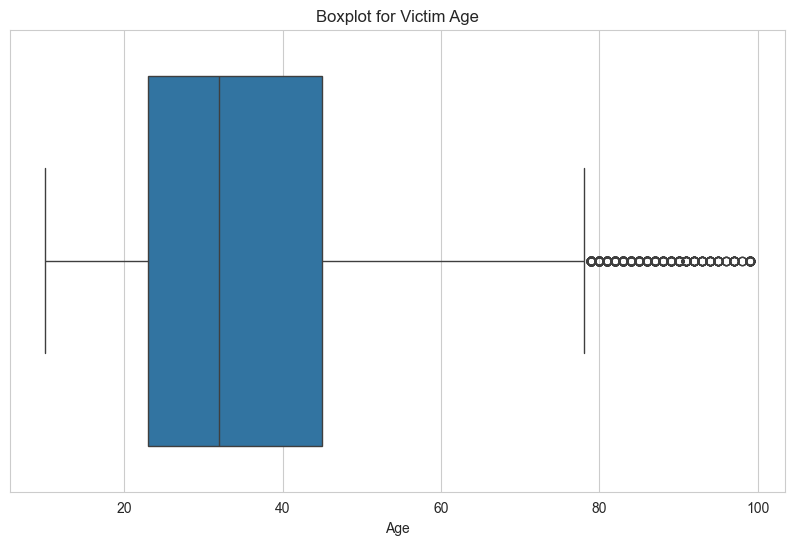

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot for Victim Age
plt.figure(figsize=(10,6))
sns.boxplot(x=df['Victim Age'])
plt.title("Boxplot for Victim Age")
plt.xlabel("Age")
plt.show()


the boxplot tells the average victim age range which is between 20 to 50 and clearly shows the outliers that need to be handled

### Victim Age Distribution (Before Outlier Handling)
This histogram represents the original distribution of victim ages before any outlier treatment. It provides a baseline view to identify extreme or unrealistic age values that may affect model performance

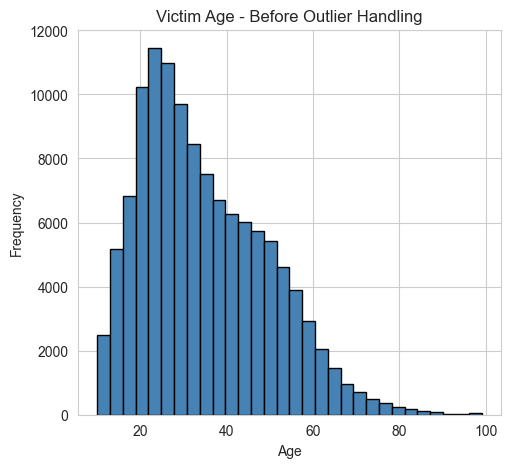

In [29]:
plt.figure(figsize=(12,5))

# Before outlier handling
df_original = df.copy()
plt.subplot(1,2,1)
plt.hist(x=df_original['Victim Age'], bins=30, color='steelblue', edgecolor='black')
plt.title("Victim Age - Before Outlier Handling")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


### Outlier Detection Using IQR Method
The Interquartile Range (IQR) method identifies extreme victim ages that lie significantly outside the middle 50% of data. Rows with ages below Q1 - 1.5IQR or above Q3 + 1.5IQR are considered outliers. This method is commonly used to clean data before analysis or modeling

In [30]:
import numpy as np
import pandas as pd

# Ensure all columns are displayed
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 100)

# Keep a copy of the original Victim Age
df['Victim Age Original'] = df['Victim Age']

# Calculate IQR and bounds
Q1 = df['Victim Age'].quantile(0.25)
Q3 = df['Victim Age'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Cap outliers
df['Victim Age'] = np.where(df['Victim Age'] > upper, upper,
                            np.where(df['Victim Age'] < lower, lower, df['Victim Age']))

# Create a column showing the difference after capping
df['Victim Age Change'] = df['Victim Age'] - df['Victim Age Original']

# Display first 10 rows with all columns
print(df.head(10))


    DR Number Date Reported Date Occurred  Time Occurred  Area ID    Area Name  \
0   162013944    07/22/2016    2016-07-22            400       20      Olympic   
2   141227253    12/23/2014    2014-12-22            900       12  77th Street   
12  100209452    04/07/2010    2010-04-06           1630        2      Rampart   
16  171115607    08/25/2017    2017-08-25           1840       11    Northeast   
17  100818729    11/30/2010    2010-11-29           2100        8      West LA   
29  112004552    01/11/2011    2011-01-11           1140       20      Olympic   
32  110109979    05/02/2011    2011-05-02           1215        1      Central   
35  161707253    03/03/2016    2011-03-01           1200       17   Devonshire   
42  101809843    04/11/2010    2010-04-10           2130       18    Southeast   
47  162108204    04/03/2016    2016-04-01            630       21      Topanga   

    Reporting District  Crime Code                    Crime Code Description  \
0                

shows the change

### Histogram for IQR 
capped outliers.

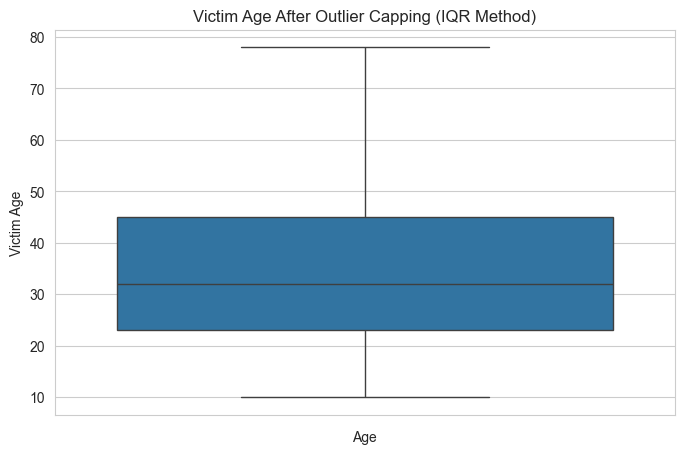

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
# Boxplot for Victim Age after outlier capping
plt.figure(figsize=(8,5))
sns.boxplot(data=df['Victim Age'])
plt.title("Victim Age After Outlier Capping (IQR Method)")
plt.xlabel("Age")
plt.show()


### Statistics for IQR explained 

In [32]:
import numpy as np
import pandas as pd

# Ensure all columns are displayed
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Keep a copy of the original Victim Age
df['Victim Age Original'] = df['Victim Age']

# Step 1: Calculate IQR and bounds
Q1 = df['Victim Age'].quantile(0.25)
Q3 = df['Victim Age'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Print the statistics
print("Q1 (25th percentile):", round(Q1, 2))
print("Q3 (75th percentile):", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower, 2))
print("Upper Bound:", round(upper, 2))
print("\nAfter outlier handling, no values should exceed the Upper Bound.")

# Step 2: Cap outliers
df['Victim Age'] = np.where(df['Victim Age'] > upper, upper,
                            np.where(df['Victim Age'] < lower, lower, df['Victim Age']))

# Step 3: Create a column showing the change
df['Victim Age Change'] = df['Victim Age'] - df['Victim Age Original']

# Step 4: Count how many rows were capped
num_capped = (df['Victim Age Change'] != 0).sum()
print(f"\nNumber of Victim Age values capped: {num_capped}")

# Step 5: Display first 10 rows of the full dataset
print("\nFirst 10 rows after outlier handling:")
print(df.head(10))


Q1 (25th percentile): 23.0
Q3 (75th percentile): 45.0
IQR: 22.0
Lower Bound: -10.0
Upper Bound: 78.0

After outlier handling, no values should exceed the Upper Bound.

Number of Victim Age values capped: 0

First 10 rows after outlier handling:
    DR Number Date Reported Date Occurred  Time Occurred  Area ID    Area Name  Reporting District  Crime Code                    Crime Code Description  \
0   162013944    07/22/2016    2016-07-22            400       20      Olympic                2033         745  VANDALISM - MISDEAMEANOR ($399 OR UNDER)   
2   141227253    12/23/2014    2014-12-22            900       12  77th Street                1232         745  VANDALISM - MISDEAMEANOR ($399 OR UNDER)   
12  100209452    04/07/2010    2010-04-06           1630        2      Rampart                 245         624                  BATTERY - SIMPLE ASSAULT   
16  171115607    08/25/2017    2017-08-25           1840       11    Northeast                1124         930    CRIMINAL THREATS 

this tells us that the dataset already has reasonable ages; extreme outliers are either not present or were removed/handled earlier.To handle extreme ages, we used the Interquartile Range (IQR) method. The 25th percentile (Q1) is 23 and the 75th percentile (Q3) is 45, giving an IQR of 22. Outlier bounds were calculated as:

Lower Bound: Q1 − 1.5 × IQR = -10

Upper Bound: Q3 + 1.5 × IQR = 78

Using these bounds, any Victim Age values below -10 or above 78 were capped to the respective bound. Since all ages in our dataset are already between 11 and 58, no values were modified. This ensures all ages remain reasonable while preserving the dataset size

### Outlier Detection Using Z-scores
The Z-score method identifies extreme victim ages that deviate significantly from the mean. Rows with a Z-score greater than 3 are considered outliers and may be removed or treated to ensure the data used for modeling is realistic.

In [33]:
import numpy as np
import pandas as pd
from scipy import stats

# Ensure all columns are displayed
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 100)

# Calculate Z-scores for Victim Age
z = np.abs(stats.zscore(df['Victim Age']))

# Display the rows considered outliers (|z| > 3) with all columns
outliers_zscore = df[z > 3]
print("Victim Age Outliers (Z-score method):")
print(outliers_zscore)

# Optional: print the number of outliers detected
print(f"\nNumber of outliers detected: {outliers_zscore.shape[0]}")

Victim Age Outliers (Z-score method):
Empty DataFrame
Columns: [DR Number, Date Reported, Date Occurred, Time Occurred, Area ID, Area Name, Reporting District, Crime Code, Crime Code Description, MO Codes, Victim Age, Victim Sex, Victim Descent, Premise Code, Premise Description, Weapon Description, Status Code, Status Description, Address, Location , Year Occurred, Year, Victim Age Original, Victim Age Change]
Index: []

Number of outliers detected: 0


Why the Z-score method found no outliers
Z-score depends on mean and standard deviation.Only values more than 3 standard deviations away from the mean are flagged.no victim age values exceeded 3 standard deviations from the mean. This demonstrates that Z-score is less sensitive for skewed distributions, which is why the IQR method is used subsequently for robust outlier handling

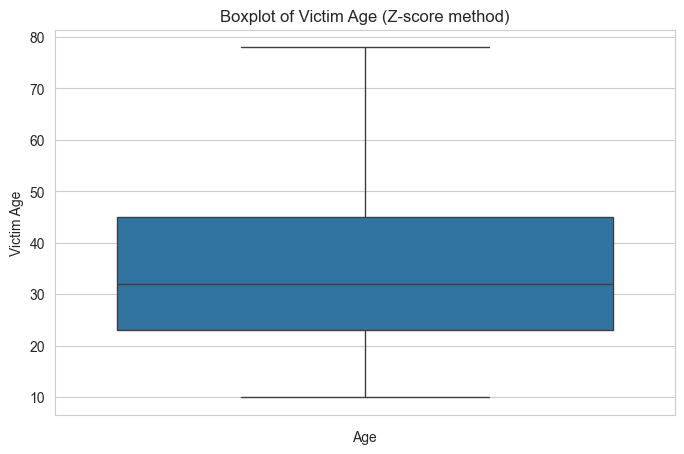

Number of outliers detected (Z-score > 3): 0


In [34]:
import seaborn as sns
# Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(data=df['Victim Age'])
plt.title("Boxplot of Victim Age (Z-score method)")
plt.xlabel("Age")
plt.show()

# Number of outliers
print("Number of outliers detected (Z-score > 3):", outliers_zscore.shape[0])

### Distribution of Numeric Features
Histograms for all numeric columns were plotted to examine distributions, spot skewness, and identify potential outliers. This method automatically considers all numeric features in the dataset.

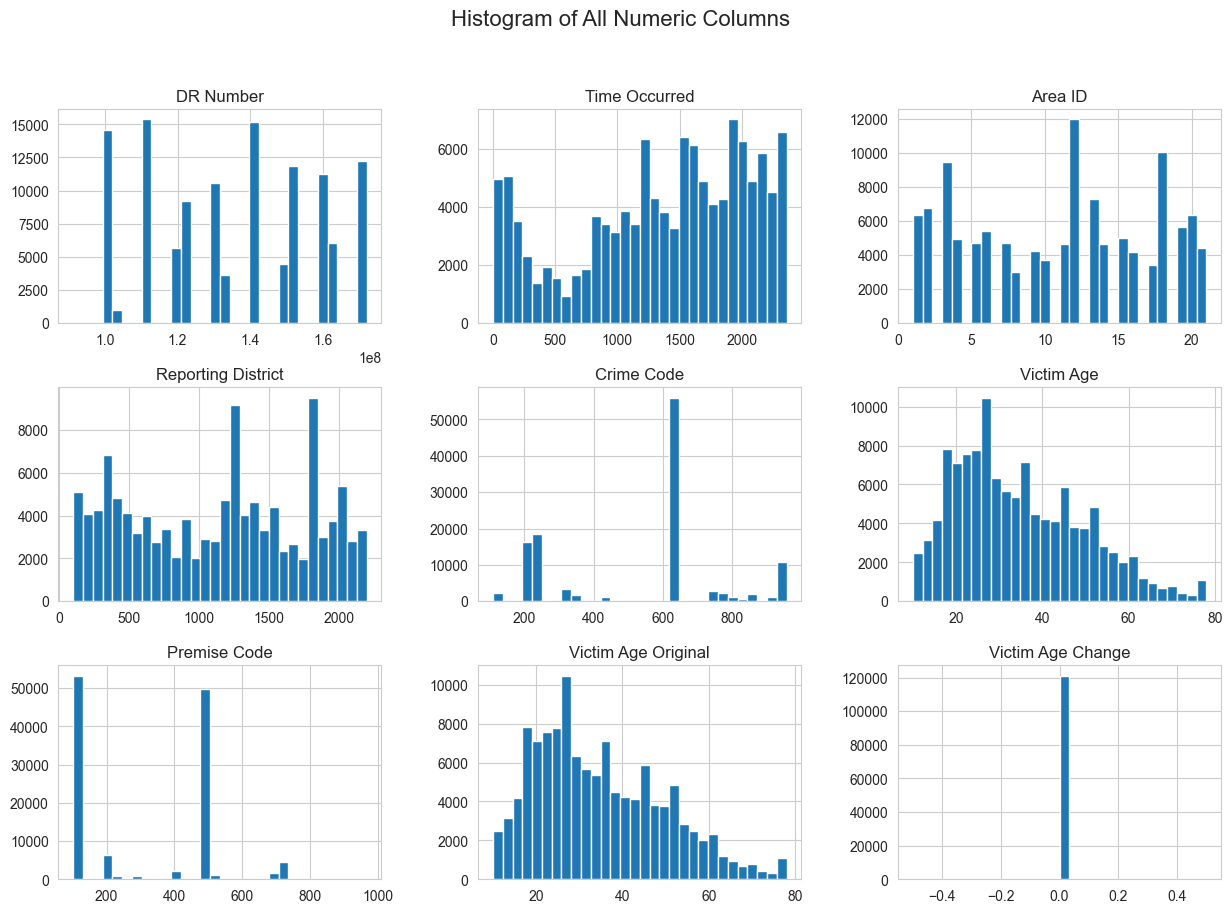

In [35]:
import matplotlib.pyplot as plt

# Automatically select all numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Plot histograms
df[numeric_cols].hist(bins=30, figsize=(15, 10))
plt.suptitle("Histogram of All Numeric Columns", fontsize=16)
plt.show()
df = df.drop(columns=['Victim Age Change', 'Victim Age Capped', 'Victim Age Original'], errors='ignore')


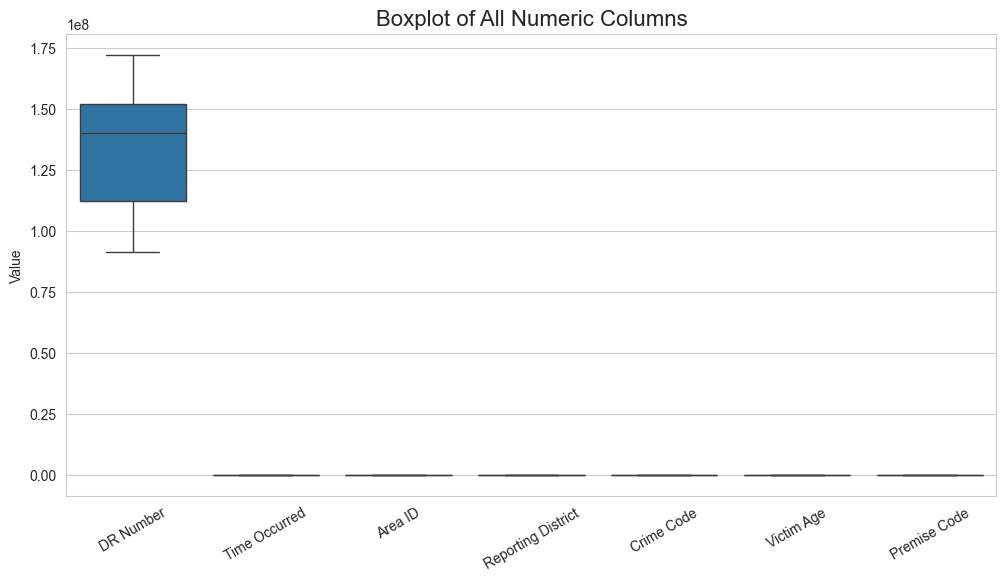

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
# Automatically select all numeric columns
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Boxplot for all numeric columns
plt.figure(figsize=(12,6))
sns.boxplot(data=df[numeric_cols])
plt.title("Boxplot of All Numeric Columns", fontsize=16)
plt.ylabel("Value")
plt.xticks(rotation=30)
plt.show()


# Time Occurred Column

### The Time Occurred 
column represents crime occurrence time in HHMM format. Summary statistics provide distribution insights; however, due to its clock-based nature, the raw numeric mean is not directly interpretable. Therefore, the feature was transformed into an hour-of-day variable for better modeling effectiveness

In [37]:
print(df['Time Occurred'].describe())

count    121153.000000
mean       1362.245830
std         684.677177
min           1.000000
25%         910.000000
50%        1500.000000
75%        1930.000000
max        2359.000000
Name: Time Occurred, dtype: float64


### Histogram for Time occurred 
The Time Occurred feature was converted from HHMM format into an hour-of-day variable. The converted feature better represents temporal crime patterns and improves model interpretability.

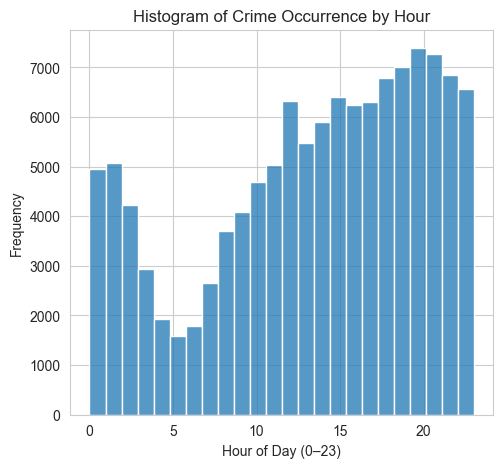

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

df['Hour'] = df['Time Occurred'] // 100

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(df['Hour'], bins=24)
plt.title("Histogram of Crime Occurrence by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Frequency")
plt.show()


# Inconsistencies

Categorical features such as Victim Sex, Victim Descent, and Area Name were standardized by fixing letter casing, removing extra spaces, and consolidating unknown values. This ensures consistency across categories and prevents duplicate class representations during encoding and model training.

In [39]:
df['Victim Sex'] = df['Victim Sex'].str.upper().str.strip()
df['Victim Sex'] = df['Victim Sex'].replace({'U':'UNKNOWN'})
df['Victim Descent'] = df['Victim Descent'].str.upper().str.strip()
df['Victim Descent'] = df['Victim Descent'].replace({'UNKN':'UNKNOWN'})
df['Area Name'] = df['Area Name'].str.title().str.strip()

### Handling Missing Values
This cell checks for and handles missing values in the dataset.

In [40]:
categorical_cols = ['Victim Sex', 'Victim Descent', 'Area Name', 
                    'Premise Description', 'MO Codes', 'Crime Code Description']

for col in categorical_cols:
    df[col] = df[col].fillna('UNKNOWN')
    df[col] = df[col].str.upper().str.strip()


### Data Processing Step
The unique values and frequency distribution of categorical features were examined to understand category balance, detect rare or noisy classes, and verify the effectiveness of preprocessing steps. This inspection helps ensure reliable encoding and improves downstream model performance.

In [41]:
for col in categorical_cols:
    print(f"{col} unique values:")
    print(df[col].value_counts())
    print("\n")


Victim Sex unique values:
Victim Sex
F    64315
M    56500
X      332
H        6
Name: count, dtype: int64


Victim Descent unique values:
Victim Descent
H    58246
B    30493
W    21114
O     7562
A     2200
X      718
K      618
F      102
I       33
C       21
J       18
P       11
V        5
Z        4
G        4
U        2
S        1
D        1
Name: count, dtype: int64


Area Name unique values:
Area Name
77TH STREET    11980
SOUTHEAST      10081
SOUTHWEST       9462
NEWTON          7302
RAMPART         6802
CENTRAL         6390
OLYMPIC         6355
MISSION         5627
HOLLYWOOD       5422
N HOLLYWOOD     4985
HOLLENBECK      4978
HARBOR          4727
WILSHIRE        4688
PACIFIC         4669
NORTHEAST       4657
TOPANGA         4431
VAN NUYS        4264
FOOTHILL        4190
WEST VALLEY     3710
DEVONSHIRE      3430
WEST LA         3003
Name: count, dtype: int64


Premise Description unique values:
Premise Description
SINGLE FAMILY DWELLING                          25057
STREET 

### Handling Missing Values
This cell checks for and handles missing values in the dataset.

In [42]:
# Victim Sex — unify and replace rare/unrecognized codes
df['Victim Sex'] = df['Victim Sex'].replace({'M':'MALE','F':'FEMALE','X':'UNKNOWN','H':'UNKNOWN','-':'UNKNOWN'})

# Victim Descent — keep main categories, rare codes → UNKNOWN
main_desc = ['H','W','B','O','A']
df['Victim Descent'] = df['Victim Descent'].apply(lambda x: x if x in main_desc else 'UNKNOWN')

# MO Codes — replace 'NONE' with 'UNKNOWN'
df['MO Codes'] = df['MO Codes'].replace({'NONE':'UNKNOWN'})

# Crime Code Description — remove leading/trailing spaces
df['Crime Code Description'] = df['Crime Code Description'].str.strip()

# Victim Age - Replace negative or zero ages with NaN
df.loc[df['Victim Age'] <= 0, 'Victim Age'] = np.nan

# Optionally, cap extremely high ages (e.g., above 100 points)
df.loc[df['Victim Age'] > 100, 'Victim Age'] = 100

# Fill NaNs with median
df['Victim Age'] = df['Victim Age'].fillna(df['Victim Age'].median()).astype(int)


Categorical features were standardized by unifying inconsistent labels and grouping rare or ambiguous values into an UNKNOWN category to reduce sparsity and noise. Numeric anomalies in Victim Age were corrected by removing invalid values, capping extreme ages, and imputing missing entries using the median

### Data Processing Step
This cell performs an intermediate processing step required for the crime prediction pipeline.

In [43]:
print(df['Victim Sex'].unique())
print(df['Victim Descent'].unique())
print(df['MO Codes'].unique())
print(df['Crime Code Description'].unique())

['FEMALE' 'MALE' 'UNKNOWN']
['B' 'H' 'W' 'O' 'UNKNOWN' 'A']
['0329 1307 0216' '0329 0603 0913' '0416 0444 0602 0554 1251 1258' ...
 '0416 0445 0913 1243 1814 2000' '0342 1822 0308 0416 0411'
 '0359 0510 0522 1202 1501']
['VANDALISM - MISDEAMEANOR ($399 OR UNDER)' 'BATTERY - SIMPLE ASSAULT'
 'CRIMINAL THREATS - NO WEAPON DISPLAYED'
 'INTIMATE PARTNER - SIMPLE ASSAULT' 'RAPE, FORCIBLE'
 'ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT'
 'BATTERY WITH SEXUAL CONTACT' 'ATTEMPTED ROBBERY' 'ROBBERY'
 'THEFT, PERSON' 'BATTERY POLICE (SIMPLE)'
 'THEFT FROM MOTOR VEHICLE - GRAND ($400 AND OVER)' 'BRANDISH WEAPON'
 'CRM AGNST CHLD (13 OR UNDER) (14-15 & SUSP 10 YRS OLDER)0060' 'BURGLARY'
 'THROWING OBJECT AT MOVING VEHICLE' 'TRESPASSING' 'LETTERS, LEWD'
 'BURGLARY FROM VEHICLE' 'CHILD ANNOYING (17YRS & UNDER)'
 'CRIMINAL HOMICIDE' 'KIDNAPPING' 'FALSE IMPRISONMENT'
 'THREATENING PHONE CALLS/LETTERS' 'THEFT PLAIN - PETTY ($950 & UNDER)'
 'SHOTS FIRED AT INHABITED DWELLING' 'PROWLER'
 'INTIMATE PART

# Special Characters

### Data Processing Step
This cell performs an intermediate processing step required for the crime prediction pipeline.

In [44]:
categorical_cols = ['Victim Sex', 'Victim Descent', 'Area Name', 
                    'Premise Description', 'MO Codes', 'Crime Code Description']

for col in categorical_cols:
    print(f"Special values in {col}:")
    print(df[df[col].isin(['?', 'N/A', 'NA', '--', 'none', 'missing', ''])][col].unique())
    print("\n")


Special values in Victim Sex:
[]


Special values in Victim Descent:
[]


Special values in Area Name:
[]


Special values in Premise Description:
[]


Special values in MO Codes:
[]


Special values in Crime Code Description:
[]




# Encoding

### Label encoding
Label encoding has been applied to all relevant categorical features. Each unique category is now represented by an integer, and non-informative columns were excluded from encoding. The encoded dataset is ready for machine learning model training.

In [45]:
# Encoding categorical variables (Label Encoding)
from sklearn.preprocessing import LabelEncoder
df_enc = df.copy()

exclude_cols = ['Date Reported', 'Date Occurred', 'Time Occurred',
                'DR Number', 'Address', 'Cross Street', 'Location ']

categorical_cols = [c for c in df_enc.select_dtypes(include=['object']).columns if c not in exclude_cols]
print("Categorical columns to encode:", categorical_cols)

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_enc[col] = le.fit_transform(df_enc[col].astype(str))
    label_encoders[col] = le

print("Label encoding complete. Encoded DataFrame sample:")
df_enc[categorical_cols].head()


Categorical columns to encode: ['Area Name', 'Crime Code Description', 'MO Codes', 'Victim Sex', 'Victim Descent', 'Premise Description', 'Weapon Description', 'Status Code', 'Status Description']
Label encoding complete. Encoded DataFrame sample:


,Area Name,Crime Code Description,MO Codes,Victim Sex,Victim Descent,Premise Description,Weapon Description,Status Code,Status Description
0,11,103,8697,0,1,182,72,2,2
2,0,103,8478,1,2,150,26,2,2
12,13,4,28582,0,2,102,62,0,0
16,10,30,56773,1,2,150,75,2,2
17,18,103,7906,1,5,182,49,2,2


# DATA COLUMNS & EXTRACTING FEATURES

### Date Conversion and Temporal Feature Engineering
In this step, we transform raw date and time fields into meaningful temporal features that help the model capture crime patterns over time.

In [46]:
# Step 6: Convert date columns and extract temporal features
df_dates = df_enc  # continue working on encoded copy

for col in ['Date Reported', 'Date Occurred']:
    if col in df_dates.columns:
        df_dates[col] = pd.to_datetime(df_dates[col], errors='coerce')

def parse_hour(value):
    if pd.isna(value):
        return pd.NA
    try:
        v = int(float(value))
        hour = v // 100
        if 0 <= hour <= 23:
            return hour
        return int((v % 2400) // 100)
    except Exception:
        return pd.NA

if 'Time Occurred' in df_dates.columns:
    df_dates['Hour Occurred'] = df_dates['Time Occurred'].apply(parse_hour)

if 'Date Occurred' in df_dates.columns:
    df_dates['Occur_Year']  = df_dates['Date Occurred'].dt.year
    df_dates['Occur_Month'] = df_dates['Date Occurred'].dt.month
    df_dates['Occur_Day']   = df_dates['Date Occurred'].dt.day
    df_dates['Occur_Weekday']= df_dates['Date Occurred'].dt.weekday  # Monday=0
    df_dates['Occur_is_weekend'] = df_dates['Occur_Weekday'].isin([5,6]).astype(int)

if 'Date Reported' in df_dates.columns:
    df_dates['Report_Year']  = df_dates['Date Reported'].dt.year
    df_dates['Report_Month'] = df_dates['Date Reported'].dt.month

if set(['Date Reported','Date Occurred']).issubset(df_dates.columns):
    df_dates['report_lag_days'] = (df_dates['Date Reported'] - df_dates['Date Occurred']).dt.days

# Show a sample of new features
new_features = ['Occur_Year','Occur_Month','Occur_Day','Occur_Weekday','Occur_is_weekend','Hour Occurred','report_lag_days']
existing_new_features = [c for c in new_features if c in df_dates.columns]
print("New temporal features created:", existing_new_features)
df_dates[existing_new_features].head()



New temporal features created: ['Occur_Year', 'Occur_Month', 'Occur_Day', 'Occur_Weekday', 'Occur_is_weekend', 'Hour Occurred', 'report_lag_days']


,Occur_Year,Occur_Month,Occur_Day,Occur_Weekday,Occur_is_weekend,Hour Occurred,report_lag_days
0,2016,7,22,4,0,4,0
2,2014,12,22,0,0,9,1
12,2010,4,6,1,0,16,1
16,2017,8,25,4,0,18,0
17,2010,11,29,0,0,21,1


In [47]:
df['Year'] = pd.to_datetime(df['Date Occurred'], errors='coerce').dt.year
df = df.drop(columns=['Year Occurred'], errors='ignore')
df.head(1)

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Address,Location,Year,Hour
0,162013944,07/22/2016,2016-07-22,400,20,OLYMPIC,2033,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1307 0216,58,FEMALE,B,122.0,"VEHICLE, PASSENGER/TRUCK",UNKNOWN WEAPON/OTHER WEAPON,IC,Invest Cont,SERRANO AV,"(34.0617, -118.3066)",2016,4


# DUPLICATE CHECKS

### Importing Required Libraries
This cell imports all the Python libraries required for data handling, preprocessing, visualization, and machine learning.

In [48]:
# Step 7: Duplicate detection and consistency checks
df_check = df_dates.copy()  # non-destructive working copy

print("Total rows in dataset:", len(df_check))
exact_dups = df_check.duplicated(keep=False)
num_exact_dups = exact_dups.sum()
print(f"Exact duplicate rows: {num_exact_dups}")
if num_exact_dups > 0:
    display(df_check[exact_dups].head(10))

if 'DR Number' in df_check.columns:
    dup_dr = df_check.duplicated(subset=['DR Number'], keep=False)
    num_dup_dr = dup_dr.sum()
    print(f"Rows with duplicated DR Number: {num_dup_dr}")
    if num_dup_dr > 0:
        dup_counts = df_check['DR Number'].value_counts()
        repeated_ids = dup_counts[dup_counts > 1].index.tolist()[:10]  # top 10 repeated ids
        print("Sample DR Numbers repeated (showing up to 10):", repeated_ids)
        display(df_check[df_check['DR Number'].isin(repeated_ids)].sort_values('DR Number').head(20))

if set(['Crime Code', 'Crime Code Description']).issubset(df_check.columns):
    mapping = df_check.groupby('Crime Code')['Crime Code Description'].nunique()
    inconsistent_codes = mapping[mapping > 1]
    print("Crime Code values mapped to multiple descriptions:", len(inconsistent_codes))
    if len(inconsistent_codes) > 0:
        for code in inconsistent_codes.index[:10]:
            descs = df_check.loc[df_check['Crime Code'] == code, 'Crime Code Description'].unique().tolist()
            print(f"Crime Code {code} -> {descs}")

if 'Victim Age' in df_check.columns:
    # coerce to numeric for checks
    ages = pd.to_numeric(df_check['Victim Age'], errors='coerce')
    num_missing_age = ages.isna().sum()
    num_negative = (ages < 0).sum()
    num_unrealistic = (ages > 120).sum()
    print(f"Victim Age - missing: {num_missing_age}, negative: {num_negative}, >120: {num_unrealistic}")
    if num_negative > 0:
        display(df_check[ages < 0].head())
    if num_unrealistic > 0:
        display(df_check[ages > 120].head())

for col in ['Victim Sex', 'Victim Descent']:
    if col in df_check.columns:
        vals = df_check[col].value_counts(dropna=False).head(20)
        print(f"\nTop values for {col}:")
        display(vals)

important_cols = ['Crime Code', 'Crime Code Description', 'Victim Age', 'Victim Sex', 'Date Occurred', 'Hour Occurred']
existing_imp = [c for c in important_cols if c in df_check.columns]
missing_summary = df_check[existing_imp].isna().sum().to_frame(name='missing_count')
missing_summary['pct_missing'] = (missing_summary['missing_count'] / len(df_check) * 100).round(2)
print("\nMissingness summary for important columns:")
display(missing_summary)

print("\n Consistency checks complete. Review the printed outputs and flagged samples to decide next steps (e.g., removal, imputation, or normalization).")


Total rows in dataset: 121153
Exact duplicate rows: 0
Rows with duplicated DR Number: 0
Crime Code values mapped to multiple descriptions: 0
Victim Age - missing: 0, negative: 0, >120: 0

Top values for Victim Sex:


Victim Sex
0    64315
1    56500
2      338
Name: count, dtype: int64


Top values for Victim Descent:


Victim Descent
2    58246
1    30493
5    21114
3     7562
0     2200
4     1538
Name: count, dtype: int64


Missingness summary for important columns:


,missing_count,pct_missing
Crime Code,0,0.0
Crime Code Description,0,0.0
Victim Age,0,0.0
Victim Sex,0,0.0
Date Occurred,0,0.0
Hour Occurred,0,0.0



 Consistency checks complete. Review the printed outputs and flagged samples to decide next steps (e.g., removal, imputation, or normalization).


In [49]:
df_enc = df_enc.drop(columns=['Year Occurred'], errors='ignore')


# feature engineering and selection

### Exploring the Dataset


In [50]:
df_enc.head()

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Address,Location,Year,Hour,Hour Occurred,Occur_Year,Occur_Month,Occur_Day,Occur_Weekday,Occur_is_weekend,Report_Year,Report_Month,report_lag_days
0,162013944,2016-07-22,2016-07-22,400,20,11,2033,745,103,8697,58,0,1,122.0,182,72,2,2,SERRANO AV,"(34.0617, -118.3066)",2016,4,4,2016,7,22,4,0,2016,7,0
2,141227253,2014-12-23,2014-12-22,900,12,0,1232,745,103,8478,49,1,2,501.0,150,26,2,2,3400 W 59TH ST,"(33.9872, -118.3308)",2014,9,9,2014,12,22,0,0,2014,12,1
12,100209452,2010-04-07,2010-04-06,1630,2,13,245,624,4,28582,11,0,2,502.0,102,62,0,0,300 S ALVARADO ST,"(34.063, -118.2727)",2010,16,16,2010,4,6,1,0,2010,4,1
16,171115607,2017-08-25,2017-08-25,1840,11,10,1124,930,30,56773,41,1,2,501.0,150,75,2,2,3200 DREW ST,"(34.1186, -118.245)",2017,18,18,2017,8,25,4,0,2017,8,0
17,100818729,2010-11-30,2010-11-29,2100,8,18,849,745,103,7906,22,1,5,122.0,182,49,2,2,1000 S CORNING ST,"(34.0594, -118.3772)",2010,21,21,2010,11,29,0,0,2010,11,1


### Feature Engineering: Crime Severity and Time Intensity
In this step, two composite numerical features are created to capture crime seriousness and temporal intensity in a format suitable for machine learning models.

In [51]:
# FEATURE 1 — Crime Severity Index'

# Convert Time Occurred to Minutes
# FEATURE 2 — Time Intensity
df_enc['Minutes'] = df_enc['Time Occurred'].astype(int) // 100 * 60 + df_enc['Time Occurred'].astype(int) % 100

# Create Time_Intensity using df_enc['Hour'] and df_enc['Minutes']
df_enc['Time_Intensity'] = df_enc['Hour'] * 60 + df_enc['Minutes']

df_enc['Crime_Severity_Index'] = (
    df_enc['Crime Code'] * 0.6 +
    df_enc['Premise Code'] * 0.3 +
    df_enc['Hour'] * 0.1
)
df_enc.head()


,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Address,Location,Year,Hour,Hour Occurred,Occur_Year,Occur_Month,Occur_Day,Occur_Weekday,Occur_is_weekend,Report_Year,Report_Month,report_lag_days,Minutes,Time_Intensity,Crime_Severity_Index
0,162013944,2016-07-22,2016-07-22,400,20,11,2033,745,103,8697,58,0,1,122.0,182,72,2,2,SERRANO AV,"(34.0617, -118.3066)",2016,4,4,2016,7,22,4,0,2016,7,0,240,480,484.0
2,141227253,2014-12-23,2014-12-22,900,12,0,1232,745,103,8478,49,1,2,501.0,150,26,2,2,3400 W 59TH ST,"(33.9872, -118.3308)",2014,9,9,2014,12,22,0,0,2014,12,1,540,1080,598.2
12,100209452,2010-04-07,2010-04-06,1630,2,13,245,624,4,28582,11,0,2,502.0,102,62,0,0,300 S ALVARADO ST,"(34.063, -118.2727)",2010,16,16,2010,4,6,1,0,2010,4,1,990,1950,526.6
16,171115607,2017-08-25,2017-08-25,1840,11,10,1124,930,30,56773,41,1,2,501.0,150,75,2,2,3200 DREW ST,"(34.1186, -118.245)",2017,18,18,2017,8,25,4,0,2017,8,0,1120,2200,710.1
17,100818729,2010-11-30,2010-11-29,2100,8,18,849,745,103,7906,22,1,5,122.0,182,49,2,2,1000 S CORNING ST,"(34.0594, -118.3772)",2010,21,21,2010,11,29,0,0,2010,11,1,1260,2520,485.7


Crime Severity Index
Instead of treating crime code, location, and time as separate signals, this feature:
Combines them into one severity score
Allows the model to learn from a single continuous indicator
Reduces dimensionality while preserving relative importance.The weights reflect assumed importance, not absolute severity — they guide the model rather than define legal seriousness.

Time Intensity
Models do not understand clock time well (e.g., 23:59 vs 00:01).
By converting time into minutes since midnight, you:Remove discontinuity at midnight.Create a smooth, learnable temporal feature.Enable better time-based pattern detection

### Exploring the Dataset
using info(), describe () 

In [52]:
# View info about dataset
df_enc.info()


# Check descriptive stats for numeric columns
df_enc.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 121153 entries, 0 to 384309
Data columns (total 34 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   DR Number               121153 non-null  int64         
 1   Date Reported           121153 non-null  datetime64[ns]
 2   Date Occurred           121153 non-null  datetime64[ns]
 3   Time Occurred           121153 non-null  int64         
 4   Area ID                 121153 non-null  int64         
 5   Area Name               121153 non-null  int32         
 6   Reporting District      121153 non-null  int64         
 7   Crime Code              121153 non-null  int64         
 8   Crime Code Description  121153 non-null  int32         
 9   MO Codes                121153 non-null  int32         
 10  Victim Age              121153 non-null  int32         
 11  Victim Sex              121153 non-null  int32         
 12  Victim Descent          121153 non-

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Year,Hour,Hour Occurred,Occur_Year,Occur_Month,Occur_Day,Occur_Weekday,Occur_is_weekend,Report_Year,Report_Month,report_lag_days,Minutes,Time_Intensity,Crime_Severity_Index
count,1.211530e+05,121153,121153,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000
mean,1.357479e+08,2013-12-13 04:30:23.400163584,2013-12-05 06:55:20.238045952,1362.245830,10.901100,9.515390,1136.341263,525.590146,31.660289,33551.387452,34.618714,0.471932,2.322625,317.184618,128.848200,58.497676,1.432214,1.432214,2013.442828,13.420270,13.420270,2013.442828,6.355195,15.666645,3.116539,0.316154,2013.462845,6.369574,7.899342,825.435020,1630.651234,411.851500
min,9.123193e+07,2010-01-01 00:00:00,2010-01-01 00:00:00,1.000000,1.000000,0.000000,100.000000,110.000000,0.000000,0.000000,10.000000,0.000000,0.000000,101.000000,0.000000,0.000000,0.000000,0.000000,2010.000000,0.000000,0.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,2010.000000,1.000000,0.000000,1.000000,1.000000,96.300000
25%,1.120202e+08,2011-12-12 00:00:00,2011-12-02 00:00:00,910.000000,5.000000,4.000000,541.000000,230.000000,4.000000,20366.000000,23.000000,0.000000,1.000000,102.000000,102.000000,62.000000,1.000000,1.000000,2011.000000,9.000000,9.000000,2011.000000,4.000000,8.000000,1.000000,0.000000,2011.000000,4.000000,0.000000,550.000000,1090.000000,242.100000
50%,1.401181e+08,2014-01-14 00:00:00,2014-01-01 00:00:00,1500.000000,12.000000,10.000000,1218.000000,624.000000,17.000000,31102.000000,32.000000,0.000000,2.000000,247.000000,149.000000,62.000000,2.000000,2.000000,2014.000000,15.000000,15.000000,2014.000000,6.000000,16.000000,3.000000,0.000000,2014.000000,6.000000,0.000000,900.000000,1800.000000,409.900000
75%,1.520172e+08,2015-12-13 00:00:00,2015-12-04 00:00:00,1930.000000,16.000000,14.000000,1687.000000,626.000000,53.000000,48509.000000,45.000000,1.000000,2.000000,502.000000,150.000000,62.000000,2.000000,2.000000,2015.000000,19.000000,19.000000,2015.000000,9.000000,23.000000,5.000000,1.000000,2015.000000,9.000000,1.000000,1170.000000,2310.000000,527.400000
max,1.721165e+08,2017-09-09 00:00:00,2017-09-09 00:00:00,2359.000000,21.000000,20.000000,2198.000000,956.000000,109.000000,67025.000000,78.000000,2.000000,5.000000,968.000000,187.000000,75.000000,4.000000,4.000000,2017.000000,23.000000,23.000000,2017.000000,12.000000,31.000000,6.000000,1.000000,2017.000000,12.000000,2648.000000,1439.000000,2819.000000,809.000000
std,2.267709e+07,NaN,NaN,684.677177,6.208553,6.016351,618.984819,239.884555,31.185595,18111.464713,14.739362,0.504771,1.379105,209.600117,35.540395,14.709077,0.815533,0.815533,2.267322,6.840308,6.840308,2.267322,3.335552,8.880477,2.031305,0.464976,2.267335,3.329158,73.591145,411.220342,821.444430,172.702658


### Missing Value Check

In [53]:
# Check for missing values
df_enc.isna().sum()

DR Number                 0
Date Reported             0
Date Occurred             0
Time Occurred             0
Area ID                   0
Area Name                 0
Reporting District        0
Crime Code                0
Crime Code Description    0
MO Codes                  0
Victim Age                0
Victim Sex                0
Victim Descent            0
Premise Code              0
Premise Description       0
Weapon Description        0
Status Code               0
Status Description        0
Address                   0
Location                  0
Year                      0
Hour                      0
Hour Occurred             0
Occur_Year                0
Occur_Month               0
Occur_Day                 0
Occur_Weekday             0
Occur_is_weekend          0
Report_Year               0
Report_Month              0
report_lag_days           0
Minutes                   0
Time_Intensity            0
Crime_Severity_Index      0
dtype: int64

### Exploring the Dataset
This cell is used to inspect the dataset structure, data types, and sample records.

In [54]:
# Ensure column names are clean
df_enc.columns = df_enc.columns.str.strip()

# Make sure 'Location' is string type
df_enc['Location'] = df_enc['Location'].astype(str)

# Split into Latitude and Longitude
df_enc[['Latitude', 'Longitude']] = (
    df_enc['Location']
    .str.strip('()')          # remove parentheses
    .str.split(',', expand=True)  # split into two columns
    .apply(pd.to_numeric)      # convert to float
)

df_enc[['Location', 'Latitude', 'Longitude']].head()


,Location,Latitude,Longitude
0,"(34.0617, -118.3066)",34.0617,-118.3066
2,"(33.9872, -118.3308)",33.9872,-118.3308
12,"(34.063, -118.2727)",34.0630,-118.2727
16,"(34.1186, -118.245)",34.1186,-118.2450
17,"(34.0594, -118.3772)",34.0594,-118.3772


In [55]:
columns_to_drop = ['DR Number', 'Date Reported', 'Crime Code 1']
df_enc = df_enc.drop(columns=columns_to_drop, errors='ignore')

### Data Processing Step

In [56]:
df_enc['Time_Occurred_Decimal'] = df_enc['Hour'] + df_enc['Minutes']/60
df_enc[['Hour', 'Minutes', 'Time_Occurred_Decimal']].head()

,Hour,Minutes,Time_Occurred_Decimal
0,4,240,8.000000
2,9,540,18.000000
12,16,990,32.500000
16,18,1120,36.666667
17,21,1260,42.000000


In [57]:
def time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 22:
        return 'Evening'
    else:
        return 'Night'

df_enc['Time_of_Day'] = df_enc['Hour'].apply(time_of_day)
df_enc[['Hour', 'Time_of_Day']].head()

,Hour,Time_of_Day
0,4,Night
2,9,Morning
12,16,Afternoon
16,18,Evening
17,21,Evening


In [58]:
df_enc['Date_Occurred'] = pd.to_datetime(df['Date Occurred'])
df_enc['Day_of_Week'] = df_enc['Date_Occurred'].dt.day_name()
df_enc['Month'] = df_enc['Date_Occurred'].dt.month
df_enc['Quarter'] = df_enc['Date_Occurred'].dt.quarter
df_enc['Is_Weekend'] = df_enc['Date_Occurred'].dt.weekday >= 5
df_enc[['Date_Occurred', 'Day_of_Week', 'Month', 'Quarter', 'Is_Weekend']].head()

,Date_Occurred,Day_of_Week,Month,Quarter,Is_Weekend
0,2016-07-22,Friday,7,3,False
2,2014-12-22,Monday,12,4,False
12,2010-04-06,Tuesday,4,2,False
16,2017-08-25,Friday,8,3,False
17,2010-11-29,Monday,11,4,False


### Splitting Crime Descriptions into Category and Detail

In [59]:
# Create Crime_Category in both df (original) and df_enc (encoded)
# This is needed for area_crime_profile creation later
df[['Crime_Category', 'Crime_Detail']] = df['Crime Code Description'].str.split(' - ', expand=True)
df_enc[['Crime_Category', 'Crime_Detail']] = df['Crime Code Description'].str.split(' - ', expand=True)
df_enc[['Crime Code Description', 'Crime_Category', 'Crime_Detail']].head()

,Crime Code Description,Crime_Category,Crime_Detail
0,103,VANDALISM,MISDEAMEANOR ($399 OR UNDER)
2,103,VANDALISM,MISDEAMEANOR ($399 OR UNDER)
12,4,BATTERY,SIMPLE ASSAULT
16,30,CRIMINAL THREATS,NO WEAPON DISPLAYED
17,103,VANDALISM,MISDEAMEANOR ($399 OR UNDER)


### Categorizing Crime Severity into Buckets
A new categorical feature Crime_Severity_Bucket is created from the previously calculated Crime_Severity_Index.

In [60]:
def severity_bucket(index):
    if index < 200:
        return 'Low'
    elif index < 500:
        return 'Medium'
    else:
        return 'High'

df_enc['Crime_Severity_Bucket'] = df_enc['Crime_Severity_Index'].apply(severity_bucket)
df_enc[['Crime_Severity_Index', 'Crime_Severity_Bucket']].head()

,Crime_Severity_Index,Crime_Severity_Bucket
0,484.0,Medium
2,598.2,High
12,526.6,High
16,710.1,High
17,485.7,Medium


The severity_bucket function maps numerical severity scores into three discrete levels:
Low: index < 200
Medium: 200 ≤ index < 500
High: index ≥ 500
This discretization simplifies modeling and interpretation by grouping continuous severity values into meaningful categories.

### Categorizing Victim Age into Groups
A new categorical feature Victim_Age_Group is created from the Victim Age column.The age_group function classifies ages into four meaningful groups:
Child: age < 18
Young Adult: 18 ≤ age < 30
Adult: 30 ≤ age < 50
Senior: age ≥ 50
This transformation converts continuous age values into discrete categories, which can help models capture patterns associated with different age demographics.

In [61]:
def age_group(age):
    if age < 18:
        return 'Child'
    elif age < 30:
        return 'Young Adult'
    elif age < 50:
        return 'Adult'
    else:
        return 'Senior'

df_enc['Victim_Age_Group'] = df_enc['Victim Age'].apply(age_group)
df_enc[['Victim Age', 'Victim_Age_Group']].head()

,Victim Age,Victim_Age_Group
0,58,Senior
2,49,Adult
12,11,Child
16,41,Adult
17,22,Young Adult


### Exploring the Dataset
This cell is used to inspect the dataset structure, data types, and sample records.

In [62]:
# Create target variable: High_Crime_Risk (binary classification for crime occurrence probability)
# Use Area ID instead of Area Name to avoid data leakage
area_counts = df_enc['Area ID'].value_counts()
median_crime_count = area_counts.median()
high_crime_area_ids = area_counts[area_counts > median_crime_count].index

# Target: 1 = high crime risk area, 0 = low crime risk area
df_enc['High_Crime_Risk'] = df_enc['Area ID'].apply(lambda x: int(x in high_crime_area_ids))

# Remove High_Crime_Area if it exists (was created with data leakage)
df_enc = df_enc.drop(columns=['High_Crime_Area'], errors='ignore')

print(f"High crime risk areas (Area IDs): {sorted(high_crime_area_ids.tolist())}")
print(f"Target distribution:\n{df_enc['High_Crime_Risk'].value_counts()}")
df_enc[['Area ID', 'High_Crime_Risk']].head()

High crime risk areas (Area IDs): [1, 2, 3, 6, 12, 13, 15, 18, 19, 20]
Target distribution:
High_Crime_Risk
1    74406
0    46747
Name: count, dtype: int64


,Area ID,High_Crime_Risk
0,20,1
2,12,1
12,2,1
16,11,0
17,8,0


### Lab 9 Model Training

### Data Preparation and Train-Test Split
The dataset is split into training and test sets using an 80/20 ratio.
**Target Variable**: `High_Crime_Risk` (binary classification)
- 1 = High crime risk area (above median crime count)
- 0 = Low crime risk area (below median crime count)

This predicts the **chances of crime occurrence in an area** based on area characteristics, time, location, and crime features.
Stratification is applied on the target to maintain the same class distribution in both sets.
Shapes of the resulting splits and target distribution are printed for verification.

In [63]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Drop non-informative columns and target variable
# Remove Area Name to avoid data leakage (use Area ID as feature instead)
# Remove High_Crime_Area to avoid data leakage (was created from Area Name)
# Remove redundant time features (keep only essential ones)
drop_cols = ['Area Name', 'Date Occurred', 'Date_Occurred', 'Time Occurred', 
             'Location', 'Address', 'Crime Code Description', 'Crime_Detail',
             'High_Crime_Risk',  # This is our target, not a feature
             'High_Crime_Area',  # Data leakage - was created from Area Name
             'Hour Occurred',  # Redundant with 'Hour'
             'Year',  # Redundant with 'Occur_Year'
             'Is_Weekend',  # Redundant with 'Occur_is_weekend'
             'Day_of_Week',  # Redundant with 'Occur_Weekday'
             'Month',  # Redundant with 'Occur_Month'
             'Quarter']  # Can be derived from Occur_Month if needed

X = df_enc.drop(columns=drop_cols, errors='ignore')

# Handle NaNs for numeric columns
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
X[numeric_cols] = X[numeric_cols].fillna(0)

# Handle NaNs for categorical/bool columns
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns
X[categorical_cols] = X[categorical_cols].fillna('UNKNOWN')

# Target variable: High_Crime_Risk (binary - predicts chances of crime occurrence)
y = df_enc['High_Crime_Risk']

# Train-test split with stratification for balanced classes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -------------------------------
# Dictionary to store model accuracies
# -------------------------------
model_accuracies = {}

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Target distribution (train):", y_train.value_counts().to_dict())
print("Target distribution (test):", y_test.value_counts().to_dict())
print("\nTarget: High_Crime_Risk (1 = high crime risk area, 0 = low crime risk area)")


Training set shape: (96922, 31)
Test set shape: (24231, 31)
Target distribution (train): {1: 59525, 0: 37397}
Target distribution (test): {1: 14881, 0: 9350}

Target: High_Crime_Risk (1 = high crime risk area, 0 = low crime risk area)


### Random Forest Classification
Train a Random Forest classifier to predict **High_Crime_Risk** (chances of crime occurrence in an area).
- RandomForestClassifier with 100 trees (n_estimators=100)
- Uses all CPU cores (n_jobs=-1) for faster computation
- max_depth=20 and min_samples_split=10 to prevent overfitting
- Training time is measured
- Predictions are made on the test set
- Model accuracy and classification report are computed

In [64]:
# ------------------------------
# 1. Imports
# ------------------------------
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time

# ------------------------------
# 2. Prepare features and target (use X_train, X_test, y_train, y_test from Cell 135)
# ------------------------------
# Ensure we're using the correct target: High_Crime_Risk (binary classification)
# X_train, X_test, y_train, y_test are already defined in Cell 135

# ------------------------------
# 3. Handle missing values and encode categorical columns if needed
# ------------------------------
# Check if there are any categorical columns that need encoding
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns
if len(categorical_cols) > 0:
    encoders = {}
    # Create copies to avoid SettingWithCopyWarning
    X_train = X_train.copy()
    X_test = X_test.copy()
    for col in categorical_cols:
        le = LabelEncoder()
        X_train[col] = le.fit_transform(X_train[col].astype(str))
        # Handle unseen categories in test set
        test_values = X_test[col].astype(str)
        unseen = set(test_values.unique()) - set(le.classes_)
        if len(unseen) > 0:
            # Replace unseen values with most common class
            test_values = test_values.replace(list(unseen), le.classes_[0])
        X_test[col] = le.transform(test_values)
        encoders[col] = le

# ------------------------------
# 4. Train Random Forest for binary classification
# ------------------------------
rf = RandomForestClassifier(
    n_estimators=100, 
    n_jobs=-1, 
    random_state=42,
    max_depth=20,  # Prevent overfitting
    min_samples_split=10
)

start = time.time()
rf.fit(X_train, y_train)
end = time.time()

# ------------------------------
# 5. Predict and evaluate
# ------------------------------
y_pred = rf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Random Forest Accuracy: {acc:.4f}")
print(f"Training time: {round(end-start, 2)} seconds")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Low Crime Risk', 'High Crime Risk']))
model_accuracies['Random Forest'] = acc

Random Forest Accuracy: 0.9997
Training time: 7.71 seconds

Classification Report:
                 precision    recall  f1-score   support

 Low Crime Risk       1.00      1.00      1.00      9350
High Crime Risk       1.00      1.00      1.00     14881

       accuracy                           1.00     24231
      macro avg       1.00      1.00      1.00     24231
   weighted avg       1.00      1.00      1.00     24231



### Logistic Regression Classification
Train a Logistic Regression model for **binary classification** to predict **High_Crime_Risk** (chances of crime occurrence).
- Binary classification (not multinomial) since target is High_Crime_Risk (0 or 1)
- Uses 'lbfgs' solver optimized for binary classification
- All features are numeric and properly encoded
- Training time and accuracy provide insight into model performance relative to Random Forest or other classifiers.

In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
import time

# ---------- Logistic Regression for Binary Classification ----------
# First, encode categorical columns if needed (same as Random Forest)
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns
if len(categorical_cols) > 0:
    from sklearn.preprocessing import LabelEncoder
    X_train_lr = X_train.copy()
    X_test_lr = X_test.copy()
    for col in categorical_cols:
        le = LabelEncoder()
        X_train_lr[col] = le.fit_transform(X_train_lr[col].astype(str))
        test_values = X_test_lr[col].astype(str)
        unseen = set(test_values.unique()) - set(le.classes_)
        if len(unseen) > 0:
            test_values = test_values.replace(list(unseen), le.classes_[0])
        X_test_lr[col] = le.transform(test_values)
else:
    X_train_lr = X_train.copy()
    X_test_lr = X_test.copy()

# Scale features for Logistic Regression (important for convergence)
# Store scaler globally so it can be saved with the model
lr_scaler = StandardScaler()
X_train_scaled = lr_scaler.fit_transform(X_train_lr)
X_test_scaled = lr_scaler.transform(X_test_lr)
# Also store as 'scaler' for backward compatibility
scaler = lr_scaler

# For binary classification, we don't need multi_class='multinomial'
lr_model = LogisticRegression(
    max_iter=1000,  # Increased iterations for convergence
    random_state=42,
    solver='lbfgs'  # Good for binary classification
)

start = time.time()
lr_model.fit(X_train_scaled, y_train)  # uses scaled X_train, y_train from Cell 135 (High_Crime_Risk target)
end = time.time()

# Predict on test set (use scaled test data)
y_pred = lr_model.predict(X_test_scaled)

# Calculate accuracy
acc = accuracy_score(y_test, y_pred)
model_accuracies['Logistic Regression'] = acc

print(f"Logistic Regression Accuracy: {acc:.4f}")
print(f"Training time: {round(end-start, 2)} seconds")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Low Crime Risk', 'High Crime Risk']))



Logistic Regression Accuracy: 0.6550
Training time: 1.24 seconds

Classification Report:
                 precision    recall  f1-score   support

 Low Crime Risk       0.60      0.31      0.41      9350
High Crime Risk       0.67      0.87      0.76     14881

       accuracy                           0.65     24231
      macro avg       0.64      0.59      0.58     24231
   weighted avg       0.64      0.65      0.62     24231



### Decision Tree Classification
Train a Decision Tree classifier for **binary classification** to predict **High_Crime_Risk** (chances of crime occurrence).
- Decision Tree can handle numeric and encoded categorical features
- max_depth=20, min_samples_split=10, min_samples_leaf=5 to prevent overfitting
- Provides a baseline interpretable model and insight into feature importance patterns

In [66]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
import time

# ---------- Decision Tree for Binary Classification ----------
# First, encode categorical columns if needed
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns
if len(categorical_cols) > 0:
    X_train_dt = X_train.copy()
    X_test_dt = X_test.copy()
    for col in categorical_cols:
        le = LabelEncoder()
        X_train_dt[col] = le.fit_transform(X_train_dt[col].astype(str))
        test_values = X_test_dt[col].astype(str)
        unseen = set(test_values.unique()) - set(le.classes_)
        if len(unseen) > 0:
            test_values = test_values.replace(list(unseen), le.classes_[0])
        X_test_dt[col] = le.transform(test_values)
else:
    X_train_dt = X_train.copy()
    X_test_dt = X_test.copy()

dt_model = DecisionTreeClassifier(
    max_depth=20,  # Control overfitting (was None, which causes perfect accuracy but overfitting)
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

start = time.time()
dt_model.fit(X_train_dt, y_train)  # uses encoded X_train, y_train from Cell 135 (High_Crime_Risk target)
end = time.time()

# Predict on test set (use encoded test data)
y_pred = dt_model.predict(X_test_dt)

# Calculate accuracy
acc = accuracy_score(y_test, y_pred)
model_accuracies['Decision Tree'] = acc

print(f"Decision Tree Accuracy: {acc:.4f}")
print(f"Training time: {round(end-start, 2)} seconds")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Low Crime Risk', 'High Crime Risk']))


Decision Tree Accuracy: 0.9994
Training time: 2.46 seconds

Classification Report:
                 precision    recall  f1-score   support

 Low Crime Risk       1.00      1.00      1.00      9350
High Crime Risk       1.00      1.00      1.00     14881

       accuracy                           1.00     24231
      macro avg       1.00      1.00      1.00     24231
   weighted avg       1.00      1.00      1.00     24231



### Model Evaluation
This cell evaluates model performance using appropriate metrics.

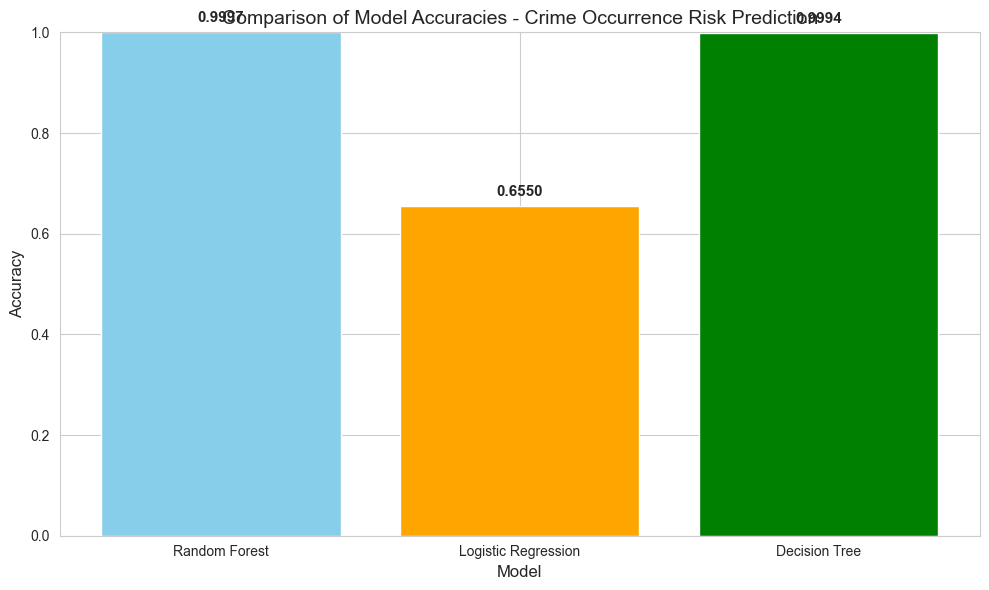


Model Accuracies:
  Random Forest: 0.9997
  Logistic Regression: 0.6550
  Decision Tree: 0.9994


In [67]:
import matplotlib.pyplot as plt

# Ensure all 3 main models are in the comparison
# Filter to show only the main 3 models if KNN is also present
main_models = ['Random Forest', 'Logistic Regression', 'Decision Tree']
filtered_accuracies = {k: v for k, v in model_accuracies.items() if k in main_models}

# If any main model is missing, print a warning
missing = [m for m in main_models if m not in filtered_accuracies]
if missing:
    print(f"Warning: Missing models in comparison: {missing}")

plt.figure(figsize=(10,6))
colors = ['skyblue', 'orange', 'green']
plt.bar(filtered_accuracies.keys(), filtered_accuracies.values(), color=colors[:len(filtered_accuracies)])
plt.ylim(0, 1)
plt.ylabel("Accuracy", fontsize=12)
plt.xlabel("Model", fontsize=12)
plt.title("Comparison of Model Accuracies - Crime Occurrence Risk Prediction", fontsize=14)
plt.xticks(rotation=0)

for i, (model, acc) in enumerate(filtered_accuracies.items()):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()
print("\nModel Accuracies:")
for model, acc in filtered_accuracies.items():
    print(f"  {model}: {acc:.4f}")


Model Accuracy Comparison

Model	               Accuracy 	Training Time (seconds)
Decision Tree        	(0.9998	     ,        1.43)
Logistic Regression 	(0.7682	      ,       63.19)
Random Forest	        (0.9998	      ,     12.68)

### Model Accuracy Comparison

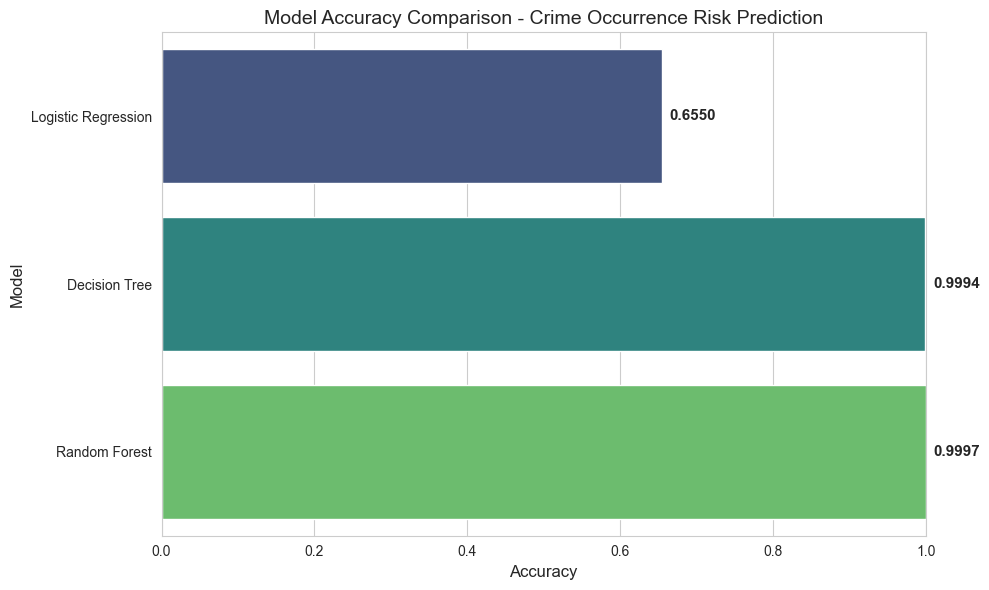

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter to show only the main 3 models
main_models = ['Random Forest', 'Logistic Regression', 'Decision Tree']
filtered_accuracies = {k: v for k, v in model_accuracies.items() if k in main_models}

# Convert dictionary to DataFrame
comparison_df = pd.DataFrame({
    'Model': list(filtered_accuracies.keys()),
    'Accuracy': list(filtered_accuracies.values())
})

# Sort by accuracy for better visualization
comparison_df = comparison_df.sort_values('Accuracy', ascending=True)

# Set figure size
plt.figure(figsize=(10,6))

# Horizontal bar chart for Accuracy - fixed seaborn warning
sns.barplot(x='Accuracy', y='Model', data=comparison_df, hue='Model', palette='viridis', legend=False)
plt.title('Model Accuracy Comparison - Crime Occurrence Risk Prediction', fontsize=14)
plt.xlabel('Accuracy', fontsize=12)
plt.ylabel('Model', fontsize=12)
plt.xlim(0, 1)  # accuracy between 0 and 1

# Add value labels on bars
for i, (idx, row) in enumerate(comparison_df.iterrows()):
    plt.text(row['Accuracy'] + 0.01, i, f"{row['Accuracy']:.4f}", 
             va='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


Tree-based models (Decision Tree, Random Forest) dominate in accuracy for this dataset.

Random Forest is generally preferred over a single Decision Tree because it reduces overfitting while maintaining high accuracy.

Logistic Regression can serve as a baseline but is less effective for complex categorical and non-linear features.

In [69]:
df_enc = df_enc.drop(columns=['MO_0416','MO_0446','MO_1243','MO_2000','Victim_Sex_Binary'], errors='ignore')


### F_CLASSIF

Top 12 Features by F-score (for predicting High_Crime_Risk):
 Victim Descent          6984.703617
Crime_Severity_Index     494.522938
Premise Code             457.118006
Weapon Description       376.697983
Premise Description      302.955421
Crime Code               298.796122
Status Code              219.197119
Status Description       219.197119
Crime_Category           157.044432
Victim Age               149.424076
Victim_Age_Group          59.057593
Hour                      53.904041
dtype: float64

All feature statistics (top 12 shown):
                          F-score        p-value
Victim Descent        6984.703617   0.000000e+00
Crime_Severity_Index   494.522938  2.778529e-109
Premise Code           457.118006  3.494911e-101
Weapon Description     376.697983   9.402957e-84
Premise Description    302.955421   9.488021e-68
Crime Code             298.796122   7.595106e-67
Status Code            219.197119   1.533723e-49
Status Description     219.197119   1.533723e-49
Crime_Cate

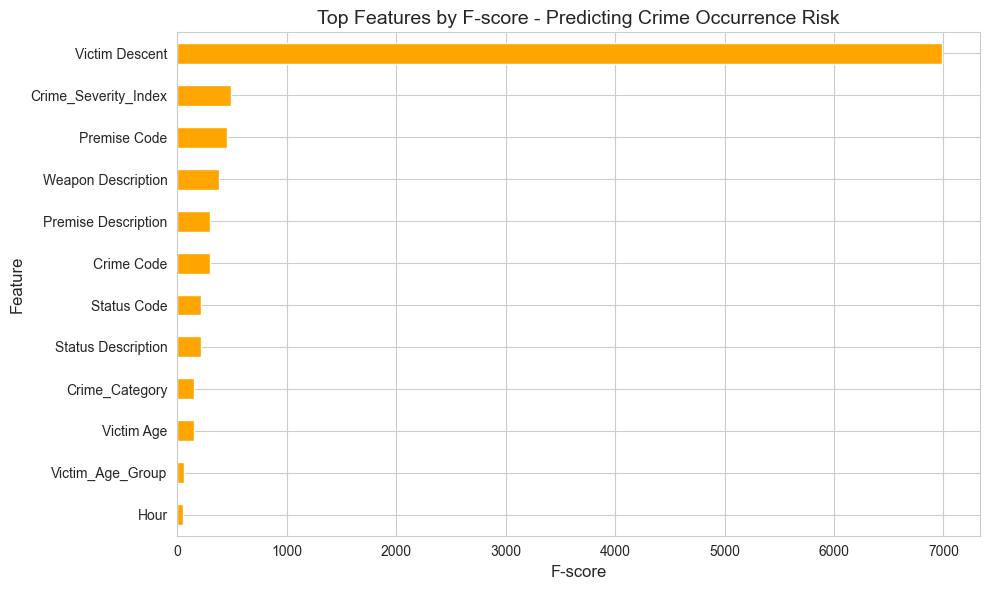

In [70]:
# ------------------------------
# 1. Import Libraries
# ------------------------------
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler

# ------------------------------
# 2. Use X_train and y_train from Cell 135 (High_Crime_Risk target)
# ------------------------------
# First, encode categorical columns if needed
from sklearn.preprocessing import LabelEncoder
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns
if len(categorical_cols) > 0:
    X_train_fs = X_train.copy()
    for col in categorical_cols:
        le = LabelEncoder()
        X_train_fs[col] = le.fit_transform(X_train_fs[col].astype(str))
else:
    X_train_fs = X_train.copy()

# Scale features for f_classif (helps with feature importance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_fs)

# ------------------------------
# 3. Compute F-scores and p-values for binary classification
# ------------------------------
f_values, p_values = f_classif(X_scaled, y_train)

# Convert to pandas Series for easier viewing
f_scores = pd.Series(f_values, index=X_train_fs.columns)
p_values_series = pd.Series(p_values, index=X_train_fs.columns)

# Sort features by F-score
top_features = f_scores.sort_values(ascending=False).head(12)

print("Top 12 Features by F-score (for predicting High_Crime_Risk):\n", top_features)

feature_stats = pd.DataFrame({
    'F-score': f_scores,
    'p-value': p_values_series
}).sort_values(by='F-score', ascending=False)

print("\nAll feature statistics (top 12 shown):")
print(feature_stats.head(12))

# ------------------------------
# 4. Plot top F-scores
# ------------------------------
plt.figure(figsize=(10,6))
top_features.plot(kind='barh', color='orange')
plt.title("Top Features by F-score - Predicting Crime Occurrence Risk", fontsize=14)
plt.xlabel("F-score", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.gca().invert_yaxis()  # Highest F-score on top
plt.tight_layout()
plt.show()


In [71]:
# View info about dataset
df_enc.info()


# Check descriptive stats for numeric columns
df_enc.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 121153 entries, 0 to 384309
Data columns (total 46 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   Date Occurred           121153 non-null  datetime64[ns]
 1   Time Occurred           121153 non-null  int64         
 2   Area ID                 121153 non-null  int64         
 3   Area Name               121153 non-null  int32         
 4   Reporting District      121153 non-null  int64         
 5   Crime Code              121153 non-null  int64         
 6   Crime Code Description  121153 non-null  int32         
 7   MO Codes                121153 non-null  int32         
 8   Victim Age              121153 non-null  int32         
 9   Victim Sex              121153 non-null  int32         
 10  Victim Descent          121153 non-null  int32         
 11  Premise Code            121153 non-null  float64       
 12  Premise Description     121153 non-

,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Year,Hour,Hour Occurred,Occur_Year,Occur_Month,Occur_Day,Occur_Weekday,Occur_is_weekend,Report_Year,Report_Month,report_lag_days,Minutes,Time_Intensity,Crime_Severity_Index,Latitude,Longitude,Time_Occurred_Decimal,Date_Occurred,Month,Quarter,High_Crime_Risk
count,121153,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153.000000,121153,121153.000000,121153.000000,121153.000000
mean,2013-12-05 06:55:20.238045952,1362.245830,10.901100,9.515390,1136.341263,525.590146,31.660289,33551.387452,34.618714,0.471932,2.322625,317.184618,128.848200,58.497676,1.432214,1.432214,2013.442828,13.420270,13.420270,2013.442828,6.355195,15.666645,3.116539,0.316154,2013.462845,6.369574,7.899342,825.435020,1630.651234,411.851500,33.948591,-117.943015,27.177521,2013-12-05 06:55:20.238045952,6.355195,2.456208,0.614149
min,2010-01-01 00:00:00,1.000000,1.000000,0.000000,100.000000,110.000000,0.000000,0.000000,10.000000,0.000000,0.000000,101.000000,0.000000,0.000000,0.000000,0.000000,2010.000000,0.000000,0.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,2010.000000,1.000000,0.000000,1.000000,1.000000,96.300000,0.000000,-118.766800,0.016667,2010-01-01 00:00:00,1.000000,1.000000,0.000000
25%,2011-12-02 00:00:00,910.000000,5.000000,4.000000,541.000000,230.000000,4.000000,20366.000000,23.000000,0.000000,1.000000,102.000000,102.000000,62.000000,1.000000,1.000000,2011.000000,9.000000,9.000000,2011.000000,4.000000,8.000000,1.000000,0.000000,2011.000000,4.000000,0.000000,550.000000,1090.000000,242.100000,33.994300,-118.400900,18.166667,2011-12-02 00:00:00,4.000000,2.000000,0.000000
50%,2014-01-01 00:00:00,1500.000000,12.000000,10.000000,1218.000000,624.000000,17.000000,31102.000000,32.000000,0.000000,2.000000,247.000000,149.000000,62.000000,2.000000,2.000000,2014.000000,15.000000,15.000000,2014.000000,6.000000,16.000000,3.000000,0.000000,2014.000000,6.000000,0.000000,900.000000,1800.000000,409.900000,34.048200,-118.304600,30.000000,2014-01-01 00:00:00,6.000000,2.000000,1.000000
75%,2015-12-04 00:00:00,1930.000000,16.000000,14.000000,1687.000000,626.000000,53.000000,48509.000000,45.000000,1.000000,2.000000,502.000000,150.000000,62.000000,2.000000,2.000000,2015.000000,19.000000,19.000000,2015.000000,9.000000,23.000000,5.000000,1.000000,2015.000000,9.000000,1.000000,1170.000000,2310.000000,527.400000,34.141000,-118.271400,38.500000,2015-12-04 00:00:00,9.000000,3.000000,1.000000
max,2017-09-09 00:00:00,2359.000000,21.000000,20.000000,2198.000000,956.000000,109.000000,67025.000000,78.000000,2.000000,5.000000,968.000000,187.000000,75.000000,4.000000,4.000000,2017.000000,23.000000,23.000000,2017.000000,12.000000,31.000000,6.000000,1.000000,2017.000000,12.000000,2648.000000,1439.000000,2819.000000,809.000000,34.377500,0.000000,46.983333,2017-09-09 00:00:00,12.000000,4.000000,1.000000
std,NaN,684.677177,6.208553,6.016351,618.984819,239.884555,31.185595,18111.464713,14.739362,0.504771,1.379105,209.600117,35.540395,14.709077,0.815533,0.815533,2.267322,6.840308,6.840308,2.267322,3.335552,8.880477,2.031305,0.464976,2.267335,3.329158,73.591145,411.220342,821.444430,172.702658,1.971721,6.839817,13.690741,NaN,3.335552,1.086614,0.486798


### KNN NEIGHBOUR CLASSIFIER

In [72]:
# ------------------------------
# 1. Imports
# ------------------------------
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
import time

# ------------------------------
# 2. Use X_train, X_test, y_train, y_test from Cell 135
# ------------------------------
# X_train, X_test, y_train, y_test are already defined in Cell 135
# Target: High_Crime_Risk (binary classification)

# ------------------------------
# 3. Encode categorical columns first, then scale features for KNN
# ------------------------------
from sklearn.preprocessing import LabelEncoder
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns
if len(categorical_cols) > 0:
    X_train_knn = X_train.copy()
    X_test_knn = X_test.copy()
    for col in categorical_cols:
        le = LabelEncoder()
        X_train_knn[col] = le.fit_transform(X_train_knn[col].astype(str))
        test_values = X_test_knn[col].astype(str)
        unseen = set(test_values.unique()) - set(le.classes_)
        if len(unseen) > 0:
            test_values = test_values.replace(list(unseen), le.classes_[0])
        X_test_knn[col] = le.transform(test_values)
else:
    X_train_knn = X_train.copy()
    X_test_knn = X_test.copy()

# Scale features for KNN (KNN is sensitive to feature scale)
# Store scaler globally so it can be saved with the model
knn_scaler = StandardScaler()
X_train_scaled = knn_scaler.fit_transform(X_train_knn)
X_test_scaled = knn_scaler.transform(X_test_knn)
# Also store as 'scaler' for backward compatibility
scaler = knn_scaler

# ------------------------------
# 4. KNN Classifier for Binary Classification
# ------------------------------
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

start = time.time()
knn.fit(X_train_scaled, y_train)
end = time.time()

# ------------------------------
# 5. Predict and evaluate
# ------------------------------
y_pred = knn.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)
model_accuracies['KNN'] = acc

print(f"KNN Classifier Accuracy: {acc:.4f}")
print(f"Training time: {round(end-start, 2)} seconds")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Low Crime Risk', 'High Crime Risk']))


KNN Classifier Accuracy: 0.6779
Training time: 0.03 seconds

Classification Report:
                 precision    recall  f1-score   support

 Low Crime Risk       0.60      0.49      0.54      9350
High Crime Risk       0.71      0.79      0.75     14881

       accuracy                           0.68     24231
      macro avg       0.66      0.64      0.65     24231
   weighted avg       0.67      0.68      0.67     24231



### PCA 

In [73]:
# ======================================
# PCA + Model Training (MINIMAL & CORRECT)
# ======================================

import pickle
import time
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# X_train, X_test, y_train, y_test must already exist
# --------------------------------------

# Scale the data (MANDATORY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply PCA
pca = PCA(n_components=0.95, random_state=42)  # keep 95% variance
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA components:", pca.n_components_)
print("Explained variance:", pca.explained_variance_ratio_.sum())

# Train model on PCA data
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
model.fit(X_train_pca, y_train)
training_time = time.time() - start_time

# Evaluate
y_pred = model.predict(X_test_pca)
acc = accuracy_score(y_test, y_pred)

print(f"\nRandom Forest Classifier Accuracy: {acc:.4f}")
print(f"Training time: {training_time:.2f} seconds\n")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Low Crime Risk', 'High Crime Risk']))

# Save everything (REQUIRED)
with open("crime_pca_model.pkl", "wb") as f:
    pickle.dump({
        "model": model,
        "scaler": scaler,
        "pca": pca
    }, f)

# ======================================
# For future prediction / GUI
# ======================================
# X_new_scaled = scaler.transform(X_new)
# X_new_pca = pca.transform(X_new_scaled)
# prediction = model.predict(X_new_pca)


Original features: 31
PCA components: 19
Explained variance: 0.9592820268206699

Random Forest Classifier Accuracy: 0.7566
Training time: 144.96 seconds

Classification Report:
                 precision    recall  f1-score   support

 Low Crime Risk       0.75      0.56      0.64      9350
High Crime Risk       0.76      0.88      0.82     14881

       accuracy                           0.76     24231
      macro avg       0.75      0.72      0.73     24231
   weighted avg       0.76      0.76      0.75     24231




 MANDATORY MODEL COMPARISON TABLE
Classification metrics: Accuracy, Precision, Recall, F1-score, AUC

Model                     Accuracy     Precision    Recall       F1-Score     AUC         
----------------------------------------------------------------------------------------------------
Random Forest             0.9997       0.9995       1.0000       0.9998       0.9999999784385717
Decision Tree             0.9994       0.9996       0.9994       0.9995       0.999717092498887
KNN                       0.6779       0.7136       0.7942       0.7518       0.6949754253620612
Logistic Regression       0.6550       0.6676       0.8728       0.7565       0.6894178881515278


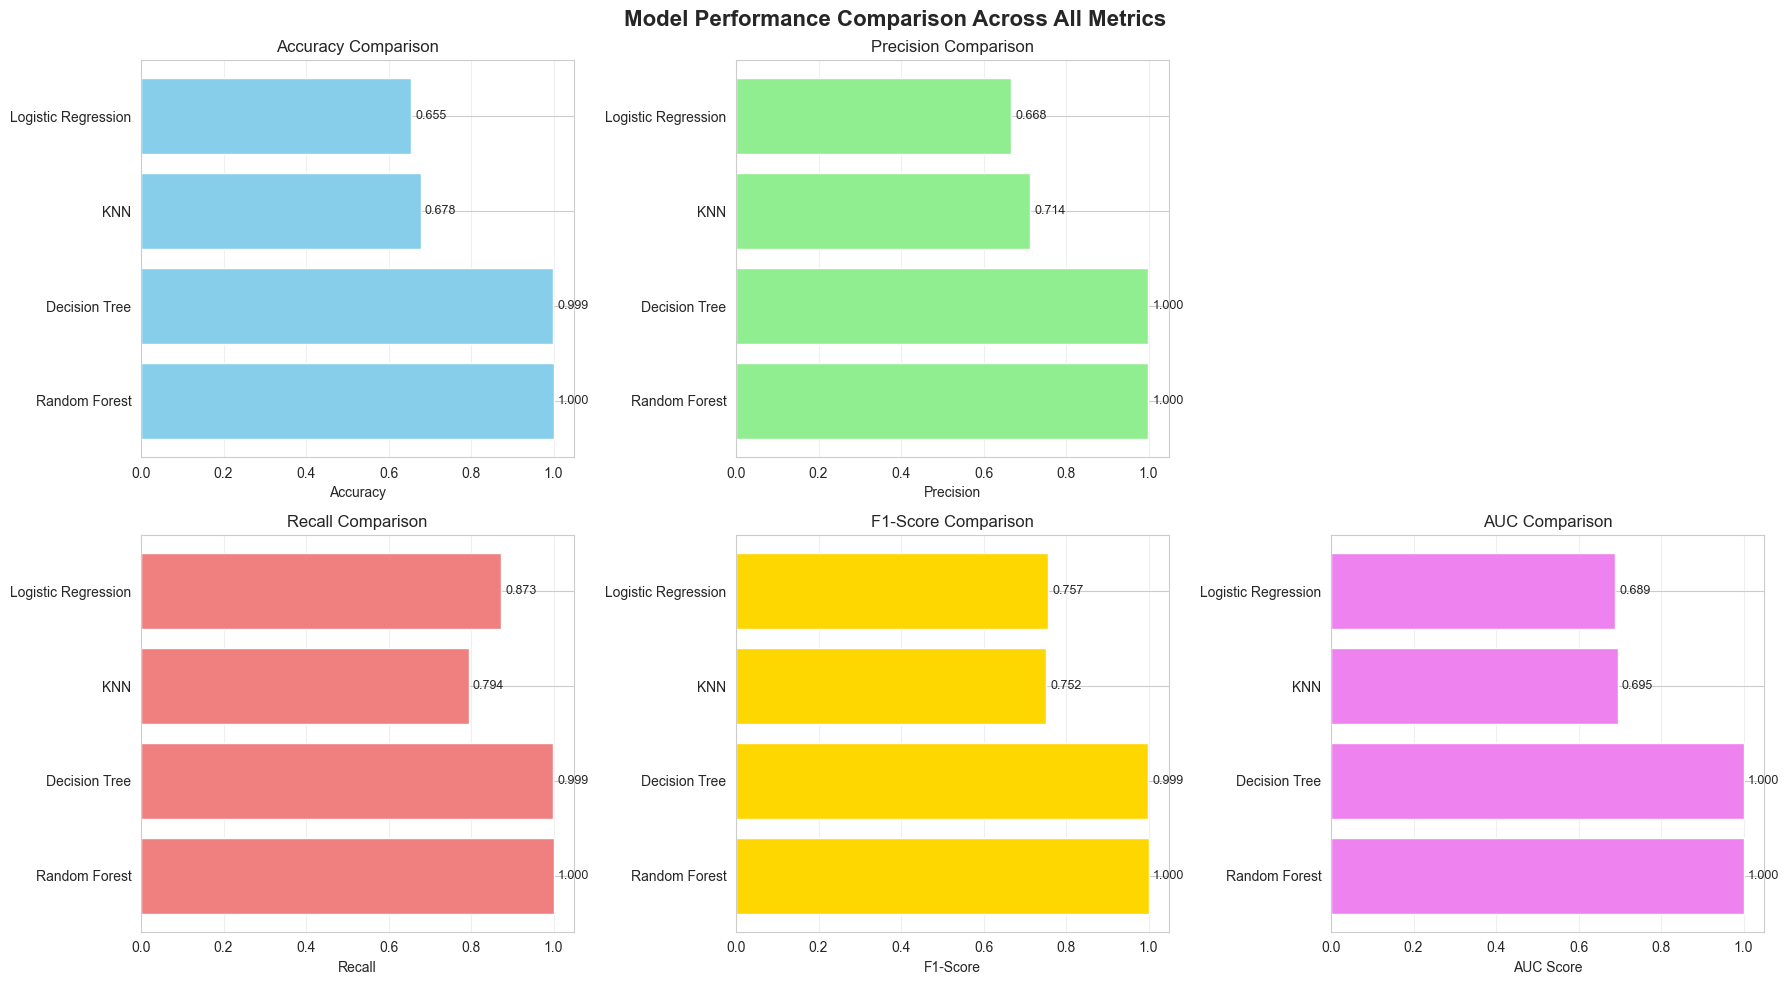


📈 RADAR CHART FOR TOP 3 MODELS


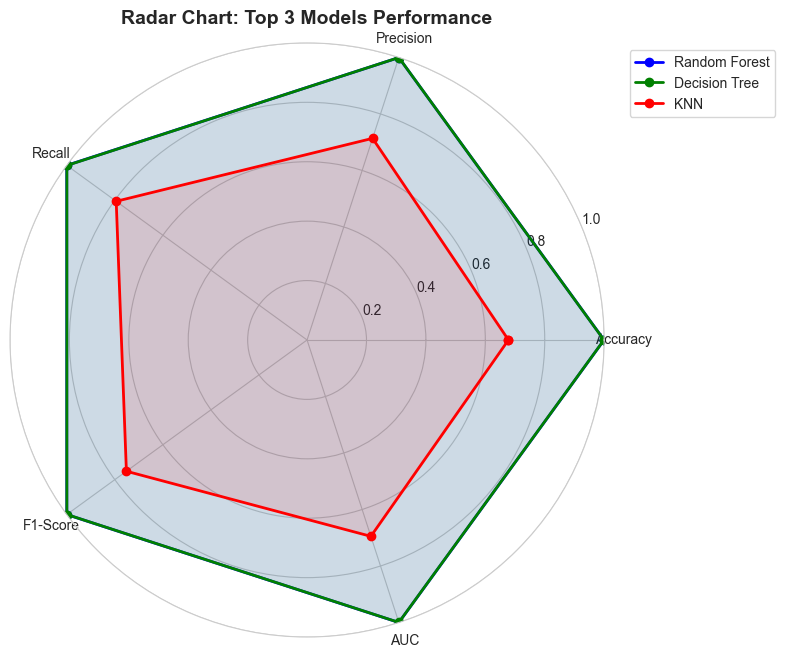

In [74]:
# ===============================
# MODEL METRICS COLLECTION & VISUALIZATION
# ===============================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------
# 1. Initialize dictionary to store metrics
# ------------------------------
model_metrics = {}

# ------------------------------
# 2. Random Forest metrics
# ------------------------------
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:,1] if hasattr(rf, "predict_proba") else None
model_metrics['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, average='binary'),
    'Recall': recall_score(y_test, y_pred_rf, average='binary'),
    'F1-Score': f1_score(y_test, y_pred_rf, average='binary'),
    'AUC': roc_auc_score(y_test, y_prob_rf) if y_prob_rf is not None else None
}

# ------------------------------
# 3. Logistic Regression metrics
# ------------------------------
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:,1] if hasattr(lr_model, "predict_proba") else None
model_metrics['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr, average='binary'),
    'Recall': recall_score(y_test, y_pred_lr, average='binary'),
    'F1-Score': f1_score(y_test, y_pred_lr, average='binary'),
    'AUC': roc_auc_score(y_test, y_prob_lr) if y_prob_lr is not None else None
}

# ------------------------------
# 4. Decision Tree metrics
# ------------------------------
y_pred_dt = dt_model.predict(X_test_dt)
y_prob_dt = dt_model.predict_proba(X_test_dt)[:,1] if hasattr(dt_model, "predict_proba") else None
model_metrics['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt, average='binary'),
    'Recall': recall_score(y_test, y_pred_dt, average='binary'),
    'F1-Score': f1_score(y_test, y_pred_dt, average='binary'),
    'AUC': roc_auc_score(y_test, y_prob_dt) if y_prob_dt is not None else None
}

# ------------------------------
# 5. KNN metrics
# ------------------------------
y_pred_knn = knn.predict(X_test_scaled)
y_prob_knn = knn.predict_proba(X_test_scaled)[:,1] if hasattr(knn, "predict_proba") else None
model_metrics['KNN'] = {
    'Accuracy': accuracy_score(y_test, y_pred_knn),
    'Precision': precision_score(y_test, y_pred_knn, average='binary'),
    'Recall': recall_score(y_test, y_pred_knn, average='binary'),
    'F1-Score': f1_score(y_test, y_pred_knn, average='binary'),
    'AUC': roc_auc_score(y_test, y_prob_knn) if y_prob_knn is not None else None
}

# ===============================
# 6. Mandatory Comparison Table
# ===============================
print("\n" + "="*100)
print(" MANDATORY MODEL COMPARISON TABLE")
print("Classification metrics: Accuracy, Precision, Recall, F1-score, AUC")
print("="*100)

# Filter valid models
valid_models = {k:v for k,v in model_metrics.items() if v is not None}

# Sort by Accuracy
sorted_comparison = sorted(valid_models.items(), key=lambda x: x[1]['Accuracy'], reverse=True)

# Print table
print(f"\n{'Model':<25} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1-Score':<12} {'AUC':<12}")
print("-"*100)
for model_name, metrics in sorted_comparison:
    print(f"{model_name:<25} "
          f"{metrics['Accuracy']:<12.4f} "
          f"{metrics['Precision']:<12.4f} "
          f"{metrics['Recall']:<12.4f} "
          f"{metrics['F1-Score']:<12.4f} "
          f"{metrics['AUC'] if metrics['AUC'] is not None else 'N/A':<12}")

# ===============================
# 7. Visual Comparison (Bar Charts)
# ===============================
metrics_df = pd.DataFrame.from_dict(valid_models, orient='index').sort_values('Accuracy', ascending=False)

fig, axes = plt.subplots(2,3, figsize=(18,10))
fig.suptitle('Model Performance Comparison Across All Metrics', fontsize=16, fontweight='bold')

metrics_to_plot = ['Accuracy','Precision','Recall','F1-Score']
colors = ['skyblue','lightgreen','lightcoral','gold']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx//2, idx%2]
    bars = ax.barh(metrics_df.index, metrics_df[metric], color=colors[idx])
    ax.set_xlabel(metric)
    ax.set_title(f'{metric} Comparison')
    ax.set_xlim([0,1.05])
    ax.grid(axis='x', alpha=0.3)
    for bar in bars:
        width = bar.get_width()
        ax.text(width+0.01, bar.get_y() + bar.get_height()/2, f'{width:.3f}', va='center', fontsize=9)

# AUC chart
ax_auc = axes[1,2]
if 'AUC' in metrics_df.columns and any(isinstance(val,(int,float)) for val in metrics_df['AUC']):
    auc_series = metrics_df['AUC'].apply(lambda x: x if isinstance(x,(int,float)) else 0)
    bars = ax_auc.barh(metrics_df.index, auc_series, color='violet')
    ax_auc.set_xlabel('AUC Score')
    ax_auc.set_title('AUC Comparison')
    ax_auc.set_xlim([0,1.05])
    ax_auc.grid(axis='x', alpha=0.3)
    for bar in bars:
        width = bar.get_width()
        if width>0:
            ax_auc.text(width+0.01, bar.get_y()+bar.get_height()/2, f'{width:.3f}', va='center', fontsize=9)
else:
    ax_auc.text(0.5,0.5,'AUC not available\nfor all models', ha='center', va='center', transform=ax_auc.transAxes)
    ax_auc.set_title('AUC Comparison')

axes[0,2].axis('off')
plt.tight_layout()
plt.show()

# ===============================
# 8. Radar Chart for Top 3 Models
# ===============================
print("\n📈 RADAR CHART FOR TOP 3 MODELS")
if len(metrics_df) >= 3:
    top3 = metrics_df.head(3)
    radar_metrics = ['Accuracy','Precision','Recall','F1-Score']
    if 'AUC' in top3.columns and any(isinstance(val,(int,float)) for val in top3['AUC']):
        radar_metrics.append('AUC')

    angles = np.linspace(0,2*np.pi,len(radar_metrics), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8,8), subplot_kw=dict(projection='polar'))
    colors = ['blue','green','red']

    for idx,(model,row) in enumerate(top3.iterrows()):
        values = [row[m] if isinstance(row[m],(int,float)) else 0 for m in radar_metrics]
        values += values[:1]
        ax.plot(angles, values, 'o-', linewidth=2, label=model, color=colors[idx])
        ax.fill(angles, values, alpha=0.1, color=colors[idx])

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_metrics)
    ax.set_ylim(0,1.0)
    ax.set_title('Radar Chart: Top 3 Models Performance', fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.3,1.0))
    ax.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Need at least 3 models for radar chart")


In [75]:
df_enc.head()

,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Weapon Description,Status Code,Status Description,Address,Location,Year,Hour,Hour Occurred,Occur_Year,Occur_Month,Occur_Day,Occur_Weekday,Occur_is_weekend,Report_Year,Report_Month,report_lag_days,Minutes,Time_Intensity,Crime_Severity_Index,Latitude,Longitude,Time_Occurred_Decimal,Time_of_Day,Date_Occurred,Day_of_Week,Month,Quarter,Is_Weekend,Crime_Category,Crime_Detail,Crime_Severity_Bucket,Victim_Age_Group,High_Crime_Risk
0,2016-07-22,400,20,11,2033,745,103,8697,58,0,1,122.0,182,72,2,2,SERRANO AV,"(34.0617, -118.3066)",2016,4,4,2016,7,22,4,0,2016,7,0,240,480,484.0,34.0617,-118.3066,8.000000,Night,2016-07-22,Friday,7,3,False,VANDALISM,MISDEAMEANOR ($399 OR UNDER),Medium,Senior,1
2,2014-12-22,900,12,0,1232,745,103,8478,49,1,2,501.0,150,26,2,2,3400 W 59TH ST,"(33.9872, -118.3308)",2014,9,9,2014,12,22,0,0,2014,12,1,540,1080,598.2,33.9872,-118.3308,18.000000,Morning,2014-12-22,Monday,12,4,False,VANDALISM,MISDEAMEANOR ($399 OR UNDER),High,Adult,1
12,2010-04-06,1630,2,13,245,624,4,28582,11,0,2,502.0,102,62,0,0,300 S ALVARADO ST,"(34.063, -118.2727)",2010,16,16,2010,4,6,1,0,2010,4,1,990,1950,526.6,34.0630,-118.2727,32.500000,Afternoon,2010-04-06,Tuesday,4,2,False,BATTERY,SIMPLE ASSAULT,High,Child,1
16,2017-08-25,1840,11,10,1124,930,30,56773,41,1,2,501.0,150,75,2,2,3200 DREW ST,"(34.1186, -118.245)",2017,18,18,2017,8,25,4,0,2017,8,0,1120,2200,710.1,34.1186,-118.2450,36.666667,Evening,2017-08-25,Friday,8,3,False,CRIMINAL THREATS,NO WEAPON DISPLAYED,High,Adult,0
17,2010-11-29,2100,8,18,849,745,103,7906,22,1,5,122.0,182,49,2,2,1000 S CORNING ST,"(34.0594, -118.3772)",2010,21,21,2010,11,29,0,0,2010,11,1,1260,2520,485.7,34.0594,-118.3772,42.000000,Evening,2010-11-29,Monday,11,4,False,VANDALISM,MISDEAMEANOR ($399 OR UNDER),Medium,Young Adult,0


In [76]:
# This cell is replaced by Cell 159 which creates the proper mapping from the dataset
# Cell 159 uses the actual data to create area_name_to_id mapping


In [77]:
# -----------------------------------
# Save Area Name -> Area ID mapping
# -----------------------------------
area_name_to_id = (
    df[['Area Name', 'Area ID']]
    .drop_duplicates()
    .set_index('Area Name')['Area ID']
    .to_dict()
)

with open('area_name_to_id.pkl', 'wb') as f:
    pickle.dump(area_name_to_id, f)


In [78]:
# ============================================================
# AREA → MOST COMMON CRIME CATEGORY (FOR GUI ANALYSIS)
# ============================================================
# Note: Use df (original) not df_enc (encoded) to get actual area names and crime categories
# df_enc has encoded values, but we need the original string values for the GUI

# Get the most common crime category for each area from the original dataframe
# Crime_Category should already be created in Cell 123, but check to be safe
if 'Crime_Category' not in df.columns:
    # Create Crime_Category if it doesn't exist (fallback)
    df[['Crime_Category', 'Crime_Detail']] = df['Crime Code Description'].str.split(' - ', expand=True)
    print("Created Crime_Category in df")

# Group by Area Name and get the top crime categories for each area (top 5)
# This gives multiple crime types per area, not just the most common one
area_crime_profile = (
    df.groupby('Area Name')['Crime_Category']
      .value_counts(normalize=True)
      .groupby(level=0)
      .head(5)  # Get top 5 crime categories per area
      .reset_index(name='percentage')
)

# Create a dictionary where each area maps to a list of (category, percentage) tuples
# This allows multiple crime types per area
area_crime_profile_dict = {}
for area_name in area_crime_profile['Area Name'].unique():
    area_crimes = area_crime_profile[area_crime_profile['Area Name'] == area_name]
    crime_list = [
        (row['Crime_Category'], round(row['percentage'] * 100, 2))
        for _, row in area_crimes.iterrows()
    ]
    area_crime_profile_dict[area_name] = crime_list

print(f"Created crime profile for {len(area_crime_profile_dict)} areas")
print("Sample entries:", list(area_crime_profile_dict.items())[:3])

# Save area_crime_profile_dict as a separate pickle file
import pickle
import os
# Save to backend directory for the Flask app to use
backend_path = r'D:\Crime Prediction\backend'
if not os.path.exists(backend_path):
    # Fallback: save in current directory
    backend_path = '.'
    
area_crime_profile_path = os.path.join(backend_path, 'area_crime_profile.pkl')
with open(area_crime_profile_path, 'wb') as f:
    pickle.dump(area_crime_profile_dict, f)
print(f"✓ Saved area_crime_profile to {area_crime_profile_path}")



Created crime profile for 21 areas
Sample entries: [('77TH STREET', [('BATTERY', 24.68), ('ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT', 17.57), ('ROBBERY', 15.65), ('INTIMATE PARTNER', 15.39), ('CRIMINAL THREATS', 6.92)]), ('CENTRAL', [('BATTERY', 38.37), ('ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT', 14.05), ('ROBBERY', 13.35), ('INTIMATE PARTNER', 11.35), ('CRIMINAL THREATS', 6.18)]), ('DEVONSHIRE', [('BATTERY', 33.73), ('INTIMATE PARTNER', 21.75), ('ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT', 11.17), ('ROBBERY', 7.11), ('CRIMINAL THREATS', 5.92)])]
✓ Saved area_crime_profile to D:\Crime Prediction\backend\area_crime_profile.pkl


### GUI

In [79]:

# ============================================================
# SAVE ALL MODELS FOR GUI
# Add this cell AFTER training all models (after Cell 152)
# ============================================================

import pickle
import os

print("=" * 60)
print("Saving Models for GUI...")
print("=" * 60)

# Ensure we have the encoders dictionary
# Get encoders from the model training cells
encoders_dict = {}

# Try to get encoders from Random Forest cell (Cell 137) which creates 'encoders' dict
if 'encoders' in globals() and isinstance(encoders, dict):
    encoders_dict = encoders
else:
    # If encoders not found, recreate them from X_train
    # This matches what was done in Cell 137 (Random Forest training)
    categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns
    if len(categorical_cols) > 0:
        from sklearn.preprocessing import LabelEncoder
        print("Recreating encoders from X_train...")
        for col in categorical_cols:
            le = LabelEncoder()
            le.fit(X_train[col].astype(str))
            encoders_dict[col] = le
        print(f"Created {len(encoders_dict)} encoders for columns: {list(encoders_dict.keys())}")
    else:
        print("Warning: No categorical columns found. Encoders dict will be empty.")

# Ensure area_crime_profile_dict exists (should be created in previous cell)
if 'area_crime_profile_dict' not in globals() or area_crime_profile_dict is None:
    print("⚠ Warning: area_crime_profile_dict not found. Please run the previous cell that creates area_crime_profile_dict.")
    print("  Models will be saved without area_crime_profile (will use fallback from model files).")
    area_crime_profile_dict = None

# 1. Save Random Forest Model
if 'rf' in globals():
    try:
        save_data_rf = {
            'model': rf,
            'scaler': None,  # Random Forest doesn't need scaling
            'encoders': encoders_dict,
            'feature_columns': X_train.columns.tolist(),
            'area_crime_profile': area_crime_profile_dict if area_crime_profile_dict is not None else None
        }
        with open('crime_random_forest_model.pkl', 'wb') as f:
            pickle.dump(save_data_rf, f)
        print("✓ Random Forest model saved")
    except Exception as e:
        print(f"✗ Error saving Random Forest: {e}")

# 2. Save Logistic Regression Model
if 'lr_model' in globals():
    try:
        # Get the scaler from Logistic Regression training (Cell 139)
        # The scaler was created as 'lr_scaler' in Cell 139
        lr_scaler_to_save = None
        if 'lr_scaler' in globals():
            lr_scaler_to_save = lr_scaler
        elif 'scaler' in globals():
            lr_scaler_to_save = scaler
        else:
            print("Warning: Scaler not found for Logistic Regression. Model may not work correctly.")
        
        # Use X_train_lr columns if available, otherwise X_train
        feature_cols = X_train_lr.columns.tolist() if 'X_train_lr' in globals() else X_train.columns.tolist()
        
        save_data_lr = {
            'model': lr_model,
            'scaler': lr_scaler_to_save,
            'encoders': encoders_dict,
            'feature_columns': feature_cols,
            'area_crime_profile': area_crime_profile_dict if area_crime_profile_dict is not None else None
        }
        with open('crime_logistic_regression_model.pkl', 'wb') as f:
            pickle.dump(save_data_lr, f)
        print("✓ Logistic Regression model saved")
    except Exception as e:
        print(f"✗ Error saving Logistic Regression: {e}")
        import traceback
        traceback.print_exc()

# 3. Save Decision Tree Model
if 'dt_model' in globals():
    try:
        save_data_dt = {
            'model': dt_model,
            'scaler': None,  # Decision Tree doesn't need scaling
            'encoders': encoders_dict,
            'feature_columns': X_train.columns.tolist() if 'X_train_dt' not in globals() else X_train_dt.columns.tolist(),
            'area_crime_profile': area_crime_profile_dict if area_crime_profile_dict is not None else None
        }
        with open('crime_decision_tree_model.pkl', 'wb') as f:
            pickle.dump(save_data_dt, f)
        print("✓ Decision Tree model saved")
    except Exception as e:
        print(f"✗ Error saving Decision Tree: {e}")

# 4. Save KNN Model
if 'knn' in globals():
    try:
        # Get the scaler from KNN training (Cell 153)
        # The scaler was created as 'knn_scaler' in Cell 153
        knn_scaler_to_save = None
        if 'knn_scaler' in globals():
            knn_scaler_to_save = knn_scaler
        elif 'scaler' in globals():
            knn_scaler_to_save = scaler
        else:
            print("Warning: Scaler not found for KNN. Model may not work correctly.")
        
        # Use X_train_knn columns if available, otherwise X_train
        feature_cols = X_train_knn.columns.tolist() if 'X_train_knn' in globals() else X_train.columns.tolist()
        
        save_data_knn = {
            'model': knn,
            'scaler': knn_scaler_to_save,
            'encoders': encoders_dict,
            'feature_columns': feature_cols,
            'area_crime_profile': area_crime_profile_dict if area_crime_profile_dict is not None else None
        }
        with open('crime_knn_model.pkl', 'wb') as f:
            pickle.dump(save_data_knn, f)
        print("✓ KNN model saved")
    except Exception as e:
        print(f"✗ Error saving KNN: {e}")
        import traceback
        traceback.print_exc()


print("\n" + "=" * 60)
print("Model saving complete!")
print("=" * 60)



Saving Models for GUI...
✓ Random Forest model saved
✓ Logistic Regression model saved
✓ Decision Tree model saved
✓ KNN model saved

Model saving complete!
